# Predicción de daño estructural post-terremoto — Proyecto integrador
## Parte 1: planteamiento del problema, dataset, calidad de datos, preprocesamiento y EDA
 **Equipo:** Ana Ferrer, Sofía Nuñez, Valentina Ramirez
**Curso:** Fundamentos de Redes Neuronales — Ciencia de Datos — Universidad de La Sabana




> **Guía del notebook (versión del repositorio).** Este notebook reúne las tres partes del proyecto integrador y se ejecuta de principio a fin en una sola sesión, porque las Partes 2 y 3 reutilizan objetos creados en la Parte 1 (`transformar()`, los estadísticos del target encoding y el parquet OOF).
>
> | Secciones | Contenido | Responsable |
> |---|---|---|
> | 0–5 | Problema, auditoría, preprocesamiento, fuga del target encoding, conjunto de prueba y EDA | Sofía Nuñez |
> | Parte 2 (M0–M5, LightGBM) | Escalera de optimización y referencia de árboles | Ana Ferrer |
> | 6–8 | Evaluación final, pipeline `predecir_dano_estructural()`, predicción sobre test, conclusiones y figuras del informe | Valentina Ramírez |
>
> Las salidas guardadas provienen de la ejecución original en Google Colab (Python 3.13). Respecto a esa versión, solo se cambiaron las rutas (celda de configuración y `savefig`) para que lea `data/raw/` y `data/processed/` y escriba en `reports/` y `data/processed/`; el historial de Git conserva el original. Para reproducir el pipeline sin ejecutar todo el notebook, ver el paquete `src/richter_predictor` y el README.


## 0. Configuración y carga única de los datos

In [36]:
import json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (f1_score, recall_score, precision_score, log_loss,
                             classification_report, confusion_matrix)
from sklearn.exceptions import ConvergenceWarning
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.width", 160, "display.max_columns", 30)

import os

# Rutas del repositorio: el notebook vive en notebooks/, los CSV de DrivenData en data/raw/
# y el parquet/metadata del preprocesamiento original en data/processed/ (ver data/README.md).
# Las variables de entorno permiten ejecutarlo desde otra ubicación (por ejemplo, Colab).
def encontrar_raiz_repo(inicio=None):
    """Sube desde la carpeta actual hasta encontrar la raíz del repositorio."""
    inicio = Path(inicio or Path.cwd()).resolve()
    for c in [inicio] + list(inicio.parents):
        if (c / "data" / "raw").is_dir() and (c / "src" / "richter_predictor").is_dir():
            return c
    return inicio

RAIZ = encontrar_raiz_repo()
DIR_RAW = Path(os.environ.get("RICHTER_DATA_RAW", RAIZ / "data" / "raw"))
DIR_PROC = Path(os.environ.get("RICHTER_DATA_PROCESSED", RAIZ / "data" / "processed"))
SALIDA = Path(os.environ.get("RICHTER_SALIDA", RAIZ))
DIR_FIG, DIR_TAB, DIR_DATOS = SALIDA / "reports" / "figures", SALIDA / "reports" / "tables", SALIDA / "data" / "processed"
for d in (DIR_FIG, DIR_TAB, DIR_DATOS):
    d.mkdir(parents=True, exist_ok=True)

requeridos = [DIR_RAW / f for f in ("train_values.csv", "train_labels.csv", "test_values.csv", "submission_format.csv")]
requeridos += [DIR_PROC / f for f in ("terremoto_train_procesado.parquet", "preprocesamiento_metadata.json")]
faltan = [str(p) for p in requeridos if not p.exists()]
if faltan:
    raise FileNotFoundError("Faltan archivos de datos (ver data/README.md):\n  " + "\n  ".join(faltan))
print(f"Datos crudos: {DIR_RAW}\nDatos procesados: {DIR_PROC}\nSalidas: {SALIDA}")

SEMILLA = 42  # la misma semilla del preprocesamiento original (metadata["random_state"])

# Paleta compartida con el informe de la Actividad 5
AZUL_CLARO, AZUL_OSCURO, NARANJA, GRIS = "#7FB3E0", "#0B3D66", "#D98E04", "#888888"
COLORES_CLASE = [AZUL_CLARO, AZUL_OSCURO, NARANJA]
NOMBRES_CLASE = {1: "1 · daño bajo", 2: "2 · daño medio", 3: "3 · daño casi total"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

def guardar_tabla(df, nombre, index=False):
    df.to_csv(DIR_TAB / f"{nombre}.csv", index=index, encoding="utf-8-sig")
    return df

# Cada archivo se lee una sola vez; el resto del notebook trabaja sobre estos objetos
t0 = time.time()
train_values = pd.read_csv(DIR_RAW / "train_values.csv")
train_labels = pd.read_csv(DIR_RAW / "train_labels.csv")
test_values = pd.read_csv(DIR_RAW / "test_values.csv")
submission_format = pd.read_csv(DIR_RAW / "submission_format.csv")
procesado = pd.read_parquet(DIR_PROC / "terremoto_train_procesado.parquet")
meta = json.loads((DIR_PROC / "preprocesamiento_metadata.json").read_text(encoding="utf-8"))
print(f"Datos cargados en {time.time() - t0:.1f} s")
for nombre, df in [("train_values", train_values), ("train_labels", train_labels),
                   ("test_values", test_values), ("submission_format", submission_format),
                   ("terremoto_train_procesado", procesado)]:
    print(f"  {nombre:<26} {df.shape[0]:>7,} filas x {df.shape[1]:>3} columnas  "
          f"({df.memory_usage(deep=True).sum() / 1e6:,.1f} MB)")

BASE detectado: /content
Contenido: ['.config', 'datos_propuesta', 'fig_matrices_confusion_escalera.png', 'fig_referencia_arboles.png', 'figuras', 'preprocesamiento_metadata.json', 'sample_data', 'submission_format.csv', 'tabla2_escalera_optimizacion.csv', 'tablas', 'terremoto_train_procesado.parquet', 'test_values.csv', 'train_labels.csv', 'train_values.csv']
Datos cargados en 1.8 s
  train_values               260,601 filas x  39 columnas  (168.9 MB)
  train_labels               260,601 filas x   2 columnas  (4.2 MB)
  test_values                 86,868 filas x  39 columnas  (56.3 MB)
  submission_format           86,868 filas x   2 columnas  (1.4 MB)
  terremoto_train_procesado  260,601 filas x 102 columnas  (224.5 MB)


## 1. Recordatorio del problema

El 25 de abril de 2015, un terremoto de magnitud 7.8 con epicentro en Gorkha, Nepal, dejó cerca de 9,000 personas fallecidas y dañó o destruyó más de 600,000 estructuras. El proyecto busca responder:

 **¿Es posible predecir el nivel de daño estructural (bajo, medio o casi total) que sufrirá un edificio ante un terremoto, a partir de sus características constructivas, los materiales utilizados y la zona geográfica en la que se ubica?**

- **Variable objetivo:** damage_grade: ordinal, 3 categorías (1 = daño bajo, 2 = daño medio, 3 = daño casi total).
- **A quién beneficia:** autoridades de gestión de riesgo, entidades de reconstrucción, aseguradoras y comunidades debido a que permite priorizar inspecciones y focalizar el refuerzo sísmico con recursos limitados.
- **Por qué red neuronal:** hay relaciones no lineales e interacciones entre variables (p. ej. el tipo de cimentación es más riesgoso en edificios de mayor altura) que un modelo lineal no captura directamente sin construir manualmente esos términos de interacción.

Esta actividad consolida el paso final técnico que es construir, entrenar, optimizar y evaluar un modelo base funcional que valide la viabilidad técnica de la solución propuesta en la Unidad 1 y 2 buscando el mejor desempeño posible y su mejor optimizacion.

## 2. Auditoría del dataset original

## 2. Descripción del dataset

**Fuente:** encuestas post-desastre de Kathmandu Living Labs y la Central Bureau of Statistics de Nepal, empaquetadas por DrivenData para la competencia Richter's Predictor (Kathmandu Living Labs & Central Bureau of Statistics, 2018).

**Tamaño:** 260,601 edificaciones de entrenamiento × 39 variables predictoras, más 86,868 edificaciones de prueba (sin etiqueta, reservadas por la competencia). Sin valores nulos ni duplicados (verificado en la Unidad 1).

**Calidad y preprocesamiento aplicado.** Antes de este notebook se dejó un dataset ya procesado (ver preprocesamiento_metadata.json), para no repetir esa limpieza en cada ejecución. Las decisiones clave, ya documentadas y justificadas:

- **age = 995** (1,390 registros): no es una edad real, es un valor especial no documentado por DrivenData. Se creó una bandera binaria (age_valor_especial_995) y se imputó con la mediana real (15 años).
- **geo_level_1_id** (31 categorías) y las 8 variables categóricas restantes con one-hot encoding (69 columnas). En múltiples soluciones públicas de esta competencia, las variables geo_level_* aparecen consistentemente entre las más predictivas, así que su codificación es una decisión central del pipeline (esto se verifica empíricamente en la Sección 4.3).
- **geo_level_2_id** (1,414 categorías) y **geo_level_3_id** (11,595 categorías) con target encoding con suavizado (evita sobreajustar en categorías con pocas observaciones), ajustado solo con el split de entrenamiento para no filtrar información del target hacia validación.
- Variables numéricas fueron estandarizadas (StandardScaler, ajustado solo con train).
- Variables binarias (has_superstructure_*, has_secondary_use*, 23 en total) sin transformar.
- **Split train/val: 80% / 20%, estratificado**, fijado desde el preprocesamiento (necesario porque el target encoding depende de qué filas son "train").

Resultado: **99 columnas de features**, sin nulos, distribución de clases preservada exactamente entre train y val.

### 2.1 Integridad de archivos e identificadores

In [37]:
predictoras = [c for c in train_values.columns if c != "building_id"]

auditoria = pd.DataFrame([
    {"archivo": "train_values.csv", "filas": len(train_values), "columnas": train_values.shape[1],
     "predictoras": len(predictoras), "nulos": int(train_values.isna().sum().sum()),
     "building_id único": train_values.building_id.is_unique},
    {"archivo": "train_labels.csv", "filas": len(train_labels), "columnas": train_labels.shape[1],
     "predictoras": 0, "nulos": int(train_labels.isna().sum().sum()),
     "building_id único": train_labels.building_id.is_unique},
    {"archivo": "test_values.csv", "filas": len(test_values), "columnas": test_values.shape[1],
     "predictoras": test_values.shape[1] - 1, "nulos": int(test_values.isna().sum().sum()),
     "building_id único": test_values.building_id.is_unique},
    {"archivo": "submission_format.csv", "filas": len(submission_format), "columnas": submission_format.shape[1],
     "predictoras": 0, "nulos": int(submission_format.isna().sum().sum()),
     "building_id único": submission_format.building_id.is_unique},
])
display(guardar_tabla(auditoria, "T01_auditoria_archivos"))

ids_train, ids_test = set(train_values.building_id), set(test_values.building_id)
chequeos = {
    "train_values y train_labels tienen el mismo conjunto de building_id": ids_train == set(train_labels.building_id),
    "train_values y train_labels están en el mismo orden": bool((train_values.building_id.values == train_labels.building_id.values).all()),
    "building_id compartidos entre train y test": len(ids_train & ids_test),
    "test_values y submission_format tienen los mismos ids en el mismo orden": bool((test_values.building_id.values == submission_format.building_id.values).all()),
    "valores de damage_grade en submission_format (plantilla)": submission_format.damage_grade.value_counts().to_dict(),
    "train y test tienen las mismas columnas en el mismo orden": list(train_values.columns) == list(test_values.columns),
}
for k, v in chequeos.items():
    print(f"- {k}: {v}")

# Unión por building_id (validate garantiza relación 1 a 1; si fallara, lanzaría un error)
datos = train_values.merge(train_labels, on="building_id", how="inner", validate="one_to_one")
print(f"\nTabla unida: {datos.shape[0]:,} filas (sin pérdida ni duplicación de registros)")

,archivo,filas,columnas,predictoras,nulos,building_id único
0,train_values.csv,260601,39,38,0,True
1,train_labels.csv,260601,2,0,0,True
2,test_values.csv,86868,39,38,0,True
3,submission_format.csv,86868,2,0,0,True


- train_values y train_labels tienen el mismo conjunto de building_id: True
- train_values y train_labels están en el mismo orden: True
- building_id compartidos entre train y test: 0
- test_values y submission_format tienen los mismos ids en el mismo orden: True
- valores de damage_grade en submission_format (plantilla): {1: 86868}
- train y test tienen las mismas columnas en el mismo orden: True

Tabla unida: 260,601 filas (sin pérdida ni duplicación de registros)


### 2.2 Diccionario de variables por grupo

In [38]:
GRUPOS = {
    "Geográfica (jerárquica)": ["geo_level_1_id", "geo_level_2_id", "geo_level_3_id"],
    "Numérica": ["count_floors_pre_eq", "age", "area_percentage", "height_percentage", "count_families"],
    "Categórica de baja cardinalidad": ["land_surface_condition", "foundation_type", "roof_type", "ground_floor_type",
                                        "other_floor_type", "position", "plan_configuration", "legal_ownership_status"],
    "Binaria: material de la superestructura": [c for c in predictoras if c.startswith("has_superstructure_")],
    "Binaria: uso secundario": [c for c in predictoras if c.startswith("has_secondary_use")],
}
assert sorted(sum(GRUPOS.values(), [])) == sorted(predictoras), "Algún predictor quedó sin grupo"

filas = []
for grupo, cols in GRUPOS.items():
    for c in cols:
        s = train_values[c]
        filas.append({"grupo": grupo, "variable": c, "tipo pandas": str(s.dtype),
                      "valores distintos (train)": s.nunique(),
                      "rango / categorías": (f"{s.min()} – {s.max()}" if s.dtype != object
                                              else ", ".join(sorted(s.unique())))})
diccionario = guardar_tabla(pd.DataFrame(filas), "T02_diccionario_variables")
resumen_grupos = diccionario.groupby("grupo", sort=False).agg(n_variables=("variable", "size"),
                                                             cardinalidad_max=("valores distintos (train)", "max"))
display(resumen_grupos)
print(f"Total de predictoras: {len(predictoras)}")
display(diccionario)

,n_variables,cardinalidad_max
grupo,,
Geográfica (jerárquica),3,11595
Numérica,5,84
Categórica de baja cardinalidad,8,10
Binaria: material de la superestructura,11,2
Binaria: uso secundario,11,2


Total de predictoras: 38


,grupo,variable,tipo pandas,valores distintos (train),rango / categorías
0,Geográfica (jerárquica),geo_level_1_id,int64,31,0 – 30
1,Geográfica (jerárquica),geo_level_2_id,int64,1414,0 – 1427
2,Geográfica (jerárquica),geo_level_3_id,int64,11595,0 – 12567
3,Numérica,count_floors_pre_eq,int64,9,1 – 9
4,Numérica,age,int64,42,0 – 995
5,Numérica,area_percentage,int64,84,1 – 100
6,Numérica,height_percentage,int64,27,2 – 32
7,Numérica,count_families,int64,10,0 – 9
8,Categórica de baja cardinalidad,land_surface_condition,object,3,"n, o, t"
9,Categórica de baja cardinalidad,foundation_type,object,5,"h, i, r, u, w"


**Lectura.** El dataset tiene **39 predictoras**, Los grupos tienen naturalezas muy distintas: tres niveles geográficos anidados (31, 1,414 y 11,595 zonas), cinco numéricas discretas, ocho categóricas con códigos anonimizados por DrivenData (letras sin significado público) y 22 binarias. Esa heterogeneidad es la razón de que cada grupo reciba una transformación diferente en la Sección 3.

### 2.3 Variable objetivo

In [39]:
conteo = datos.damage_grade.value_counts().sort_index()
dist_clases = pd.DataFrame({"clase": conteo.index, "significado": [NOMBRES_CLASE[c] for c in conteo.index],
                            "frecuencia": conteo.values, "porcentaje": (conteo.values / len(datos) * 100).round(2)})
display(guardar_tabla(dist_clases, "T03_distribucion_clases"))
print(f"Razón mayoritaria/minoritaria: {conteo.max() / conteo.min():.1f}")
print(f"Exactitud de predecir siempre la clase 2: {conteo[2] / len(datos):.4f}")
print(f"F1 macro de predecir siempre la clase 2: "
      f"{f1_score(datos.damage_grade, np.full(len(datos), 2), average='macro'):.4f}")

,clase,significado,frecuencia,porcentaje
0,1,1 · daño bajo,25124,9.64
1,2,2 · daño medio,148259,56.89
2,3,3 · daño casi total,87218,33.47


Razón mayoritaria/minoritaria: 5.9
Exactitud de predecir siempre la clase 2: 0.5689
F1 macro de predecir siempre la clase 2: 0.2417


### 2.4 Duplicados, valores especiales y rangos numéricos

In [40]:
dup_ids = int(datos.building_id.duplicated().sum())
dup_mask = datos.duplicated(subset=predictoras, keep=False)
grupos_dup = datos[dup_mask].groupby(predictoras, sort=False).damage_grade.agg(["size", "nunique"])
filas_en_conflicto = int(grupos_dup.loc[grupos_dup["nunique"] > 1, "size"].sum())
test_igual_train = test_values[predictoras].merge(train_values[predictoras].drop_duplicates(), how="inner").shape[0]

duplicados = pd.DataFrame([
    {"chequeo": "building_id repetidos en train", "valor": dup_ids},
    {"chequeo": "filas idénticas en las 38 predictoras (copias además de la primera)",
     "valor": int(datos.duplicated(subset=predictoras).sum())},
    {"chequeo": "filas que pertenecen a un grupo de perfiles idénticos", "valor": int(dup_mask.sum())},
    {"chequeo": "grupos de perfiles idénticos", "valor": len(grupos_dup)},
    {"chequeo": "grupos idénticos con etiquetas distintas", "valor": int((grupos_dup["nunique"] > 1).sum())},
    {"chequeo": "filas dentro de grupos con etiquetas distintas", "valor": filas_en_conflicto},
    {"chequeo": "filas de test idénticas a algún perfil de train", "valor": test_igual_train},
])
display(guardar_tabla(duplicados, "T04_duplicados"))

NUMERICAS = GRUPOS["Numérica"]
desc = datos[NUMERICAS].describe(percentiles=[.25, .5, .75, .99]).T.round(2)
display(guardar_tabla(desc, "T05_resumen_numericas", index=True))

edad = datos.age
print(f"age = 995: {int((edad == 995).sum()):,} registros en train ({(edad == 995).mean()*100:.2f} %), "
      f"{int((test_values.age == 995).sum()):,} en test")
print(f"Siguiente valor más alto de age después de 995: {edad[edad != 995].max()}")
print("Valores de age por encima de 100:", edad[edad > 100].value_counts().sort_index().to_dict())
print("\nDistribución de damage_grade en age = 995 (%):",
      (datos.loc[edad == 995, "damage_grade"].value_counts(normalize=True).sort_index() * 100).round(1).to_dict())
print("Distribución global (%):", (datos.damage_grade.value_counts(normalize=True).sort_index() * 100).round(1).to_dict())

,chequeo,valor
0,building_id repetidos en train,0
1,filas idénticas en las 38 predictoras (copias ...,16191
2,filas que pertenecen a un grupo de perfiles id...,28544
3,grupos de perfiles idénticos,12353
4,grupos idénticos con etiquetas distintas,3825
5,filas dentro de grupos con etiquetas distintas,9624
6,filas de test idénticas a algún perfil de train,9255


,count,mean,std,min,25%,50%,75%,99%,max
count_floors_pre_eq,260601.0,2.13,0.73,1.0,2.0,2.0,2.0,4.0,9.0
age,260601.0,26.54,73.57,0.0,10.0,15.0,30.0,100.0,995.0
area_percentage,260601.0,8.02,4.39,1.0,5.0,7.0,9.0,23.0,100.0
height_percentage,260601.0,5.43,1.92,2.0,4.0,5.0,6.0,11.0,32.0
count_families,260601.0,0.98,0.42,0.0,1.0,1.0,1.0,2.0,9.0


age = 995: 1,390 registros en train (0.53 %), 461 en test
Siguiente valor más alto de age después de 995: 200
Valores de age por encima de 100: {105: 89, 110: 100, 115: 21, 120: 180, 125: 37, 130: 9, 135: 5, 140: 9, 145: 3, 150: 142, 155: 1, 160: 6, 165: 2, 170: 6, 175: 5, 180: 7, 185: 1, 190: 3, 195: 2, 200: 106, 995: 1390}

Distribución de damage_grade en age = 995 (%): {1: 12.9, 2: 59.1, 3: 28.0}
Distribución global (%): {1: 9.6, 2: 56.9, 3: 33.5}


**Lectura.** No hay nulos ni `building_id` repetidos, y características y etiquetas se relacionan 1 a 1. Sí hay **16,191 filas que repiten exactamente el perfil de otra** en las 38 predictoras (12,353 perfiles repetidos que agrupan 28,544 filas). En 3,825 de esos perfiles conviven etiquetas distintas (9,624 filas): dos edificios con la misma descripción sufrieron daños diferentes. No es un error que haya que borrar, porque el cuestionario no recoge todo lo que determina el daño (calidad de la obra, suelo exacto, intensidad local del sismo), pero sí indica que existe un **error irreducible**: ningún modelo puede acertar todas esas filas a la vez. Por eso los duplicados se conservan.

Sobre `age`: los valores van de 0 a 200 en múltiplos de 5 y luego saltan a **995** (1,390 registros en train, 0.53 %; 461 en test). Ese salto y la distribución de daño distinta en ese grupo (12.9 % de daño bajo frente a 9.6 % global) son consistentes con un código especial y no con una edad real. Su peso numérico es grande: en los datos originales `age` tiene media 26.5 y desviación 73.6 años; con la imputación, el split de train queda con media 21.3 y desviación 19.6 (Tabla T07). Sin ese tratamiento, el `StandardScaler` comprimiría casi todas las edades reales en un rango muy estrecho alrededor de cero.

## 3. Comparación entre el dataset original y el procesado
se **reconstruye cada transformación desde los CSV originales** y se compara numéricamente con el parquet. Una diferencia máxima del orden de 1e-15 significa coincidencia exacta (error de redondeo de coma flotante).

In [41]:
print(f"Parquet: {procesado.shape[0]:,} filas x {procesado.shape[1]} columnas "
      f"= building_id + split + damage_grade + {len(meta['feature_cols'])} features")
print("Claves del metadata:", list(meta))
print("¿Todas las feature_cols están en el parquet?", set(meta["feature_cols"]) <= set(procesado.columns))
print("¿El parquet conserva el orden y los ids de train_values?",
      bool((procesado.building_id.values == datos.building_id.values).all()))
print("¿damage_grade del parquet = etiquetas originales?",
      bool((procesado.damage_grade.values == datos.damage_grade.values).all()))
print("Nulos en las features procesadas:", int(procesado[meta["feature_cols"]].isna().sum().sum()))
composicion = pd.DataFrame({
    "bloque": ["one-hot (8 categóricas + geo_level_1_id)", "numéricas estandarizadas", "target encoding estandarizado",
               "binarias originales", "bandera age = 995"],
    "columnas": [len(meta["onehot_cols"]), 5, 2, len(meta["bin_cols"]) - 1, 1]})
composicion.loc[len(composicion)] = ["total", composicion.columnas.sum()]
display(composicion)

Parquet: 260,601 filas x 102 columnas = building_id + split + damage_grade + 99 features
Claves del metadata: ['feature_cols', 'onehot_cols', 'scaled_cols', 'bin_cols', 'num_cols_final', 'cat_baja_cardinalidad', 'cat_alta_cardinalidad', 'categorias_por_columna', 'mediana_age_normal', 'media_global_damage_grade', 'smoothing_m', 'random_state', 'val_size', 'n_train', 'n_val', 'n_test']
¿Todas las feature_cols están en el parquet? True
¿El parquet conserva el orden y los ids de train_values? True
¿damage_grade del parquet = etiquetas originales? True
Nulos en las features procesadas: 0


,bloque,columnas
0,one-hot (8 categóricas + geo_level_1_id),69
1,numéricas estandarizadas,5
2,target encoding estandarizado,2
3,binarias originales,22
4,bandera age = 995,1
5,total,99


### 3.1 División entrenamiento/validación

In [42]:
es_train = (procesado.split == "train").values
es_val = ~es_train

# ¿Se puede reproducir el split exacto con la semilla del metadata?
_, val_rep = train_test_split(datos, test_size=meta["val_size"], random_state=meta["random_state"],
                              stratify=datos.damage_grade)
print("train_test_split(test_size=0.2, random_state=42, stratify=damage_grade) reproduce el split:",
      set(val_rep.building_id) == set(procesado.loc[es_val, "building_id"]))
print("Intersección de ids train/val:",
      len(set(procesado.loc[es_train, "building_id"]) & set(procesado.loc[es_val, "building_id"])))

tabla_split = (pd.crosstab(procesado.split, procesado.damage_grade, margins=True, margins_name="total")
                 .reindex(["train", "val", "total"]))
porc = pd.crosstab(procesado.split, procesado.damage_grade, normalize="index").mul(100).round(2)
split_df = pd.DataFrame({
    "split": ["train", "val"],
    "registros": [int(es_train.sum()), int(es_val.sum())],
    "proporción del total (%)": [round(es_train.mean() * 100, 2), round(es_val.mean() * 100, 2)],
    "clase 1 (%)": porc.loc[["train", "val"], 1].values,
    "clase 2 (%)": porc.loc[["train", "val"], 2].values,
    "clase 3 (%)": porc.loc[["train", "val"], 3].values,
})
display(guardar_tabla(split_df, "T06_split_train_val"))
display(tabla_split)

train_test_split(test_size=0.2, random_state=42, stratify=damage_grade) reproduce el split: True
Intersección de ids train/val: 0


,split,registros,proporción del total (%),clase 1 (%),clase 2 (%),clase 3 (%)
0,train,208480,80.0,9.64,56.89,33.47
1,val,52121,20.0,9.64,56.89,33.47


damage_grade,1,2,3,total
split,,,,
train,20099,118607,69774,208480
val,5025,29652,17444,52121
total,25124,148259,87218,260601


### 3.2 Valor especial `age = 995`, escalado numérico, one-hot y binarias

In [43]:
tr = datos[es_train]  # vista del split de entrenamiento con las variables originales

# age: bandera + imputación con la mediana de la edad real calculada SOLO en train
mediana_tr = tr.loc[tr.age != 995, "age"].median()
mediana_todo = datos.loc[datos.age != 995, "age"].median()
bandera_ok = bool(((datos.age == 995).astype(int).values == procesado.age_valor_especial_995.values).all())
print(f"Mediana de age real: train = {mediana_tr}, todo el train original = {mediana_todo}, metadata = {meta['mediana_age_normal']}")
print("La bandera age_valor_especial_995 coincide exactamente con age == 995:", bandera_ok)

# StandardScaler: se prueba si sus parámetros salen de train o de todo el dataset
def num_base(df):
    out = df[NUMERICAS].astype(float).copy()
    out["age"] = out["age"].where(df["age"] != 995, meta["mediana_age_normal"])
    return out

num_todo = num_base(datos)
filas = []
for c in NUMERICAS:
    col_s = f"{c}_s"
    for origen, ref in [("solo train", num_todo[es_train]), ("train + val", num_todo)]:
        mu, sd = ref[c].mean(), ref[c].std(ddof=0)
        filas.append({"variable": c, "parámetros ajustados con": origen, "media": round(mu, 4), "desv. est.": round(sd, 4),
                      "max |diferencia| con el parquet": float(np.abs((num_todo[c] - mu) / sd - procesado[col_s]).max())})
escalado = guardar_tabla(pd.DataFrame(filas), "T07_verificacion_escalado")
display(escalado)

# One-hot: la columna c_k del parquet debe ser 1 exactamente cuando la variable original vale k
errores_oh = 0
for c, cats in meta["categorias_por_columna"].items():
    for k in cats:
        errores_oh += int(((datos[c].astype(str) == k).astype(int).values != procesado[f"{c}_{k}"].values).sum())
print(f"\nCeldas one-hot que no coinciden con la variable original: {errores_oh}")
print("Cada fila tiene exactamente un 1 por variable categórica:",
      all((procesado[[f"{c}_{k}" for k in cats]].sum(axis=1) == 1).all() for c, cats in meta["categorias_por_columna"].items()))

binarias_orig = GRUPOS["Binaria: material de la superestructura"] + GRUPOS["Binaria: uso secundario"]
print("Binarias idénticas a las originales:", bool((datos[binarias_orig].values == procesado[binarias_orig].values).all()),
      f"({len(binarias_orig)} binarias originales + 1 bandera = {len(meta['bin_cols'])})")

Mediana de age real: train = 15.0, todo el train original = 15.0, metadata = 15.0
La bandera age_valor_especial_995 coincide exactamente con age == 995: True


,variable,parámetros ajustados con,media,desv. est.,max |diferencia| con el parquet
0,count_floors_pre_eq,solo train,2.1294,0.7270,5.631051e-13
1,count_floors_pre_eq,train + val,2.1297,0.7277,9.455437e-03
2,age,solo train,21.3213,19.5802,4.014566e-13
3,age,train + val,21.3079,19.5599,1.016224e-02
4,area_percentage,solo train,8.0163,4.3995,1.950440e-12
5,area_percentage,train + val,8.0181,4.3922,3.439566e-02
6,height_percentage,solo train,5.4323,1.9096,8.455459e-13
7,height_percentage,train + val,5.4344,1.9184,6.511128e-02
8,count_families,solo train,0.9837,0.4183,2.181366e-11
9,count_families,train + val,0.9839,0.4184,6.326005e-03



Celdas one-hot que no coinciden con la variable original: 0
Cada fila tiene exactamente un 1 por variable categórica: True
Binarias idénticas a las originales: True (22 binarias originales + 1 bandera = 23)


### 3.3 Target encoding de `geo_level_2_id` y `geo_level_3_id`: ¿cómo se calculó realmente?

La documentación afirma que el encoding se ajustó solo con el split de entrenamiento, lo que protege a **validación**. Falta comprobar qué valor recibió cada fila **de entrenamiento**. Se comparan tres hipótesis de construcción contra el parquet:

- **A. Media suavizada con todas las filas de train** (incluye la etiqueta de la propia fila): $\;TE(g) = \dfrac{\sum_{i \in g} y_i + m\,\bar y}{n_g + m}$, con $m = 15$ y $\bar y$ la media global de train.
- **B. Leave-one-out:** la misma fórmula excluyendo la fila que se codifica.
- **C. Ajustado con train + val** (fuga hacia validación).

El valor estandarizado del parquet se compara con cada hipótesis tras aplicarle el mismo `StandardScaler` (ajustado con train).

In [44]:
m_suav, media_global = meta["smoothing_m"], meta["media_global_damage_grade"]
y_all = datos.damage_grade.astype(float)
print(f"Media global de damage_grade en train = {y_all[es_train].mean():.10f} (metadata: {media_global:.10f})")

def te_estadisticos(geo, y):
    st = pd.DataFrame({"g": geo, "y": y}).groupby("g").y.agg(["sum", "count"])
    return st

def te_aplicar(geo, st, m=m_suav, prior=media_global):
    s = geo.map(st["sum"]); n = geo.map(st["count"])
    return ((s + m * prior) / (n + m)).fillna(prior)  # categorías no vistas -> media global

def estandarizar_con_train(v):
    mu, sd = v[es_train].mean(), v[es_train].std(ddof=0)
    return (v - mu) / sd, mu, sd

filas, te_reconstruido = [], {}
for nivel in meta["cat_alta_cardinalidad"]:
    geo, col_s = datos[nivel], procesado[f"{nivel}_target_enc_s"].values
    st_tr = te_estadisticos(geo[es_train], y_all[es_train])
    # Hipótesis A
    te_A = te_aplicar(geo, st_tr)
    za, mu_a, sd_a = estandarizar_con_train(te_A)
    # Hipótesis B (LOO solo en las filas de train; validación igual que A)
    s_g, n_g = geo.map(st_tr["sum"]), geo.map(st_tr["count"])
    te_B = te_A.copy()
    te_B[es_train] = ((s_g - y_all + m_suav * media_global) / (n_g - 1 + m_suav))[es_train]
    zb, _, _ = estandarizar_con_train(te_B)
    # Hipótesis C (estadísticos con train + val)
    te_C = te_aplicar(geo, te_estadisticos(geo, y_all), prior=y_all.mean())
    zc, _, _ = estandarizar_con_train(te_C)
    te_reconstruido[nivel] = {"te": te_A, "mu": mu_a, "sd": sd_a, "stats": st_tr}
    for hip, z in [("A: todas las filas de train (incluye la propia)", za), ("B: leave-one-out", zb),
                   ("C: train + val", zc)]:
        filas.append({"variable": nivel, "hipótesis": hip,
                      "max |dif| en train": float(np.abs(z[es_train] - col_s[es_train]).max()),
                      "max |dif| en val": float(np.abs(z[es_val] - col_s[es_val]).max())})
    no_vistas = int((~geo[es_val].isin(st_tr.index)).sum())
    print(f"{nivel}: {geo.nunique():,} categorías; {len(st_tr):,} vistas en train; "
          f"{no_vistas} filas de val con categoría no vista en train (reciben la media global)")

hipotesis = guardar_tabla(pd.DataFrame(filas), "T08_reconstruccion_target_encoding")
display(hipotesis)

Media global de damage_grade en train = 2.2382722563 (metadata: 2.2382722563)
geo_level_2_id: 1,414 categorías; 1,409 vistas en train; 5 filas de val con categoría no vista en train (reciben la media global)
geo_level_3_id: 11,595 categorías; 11,380 vistas en train; 257 filas de val con categoría no vista en train (reciben la media global)


,variable,hipótesis,max |dif| en train,max |dif| en val
0,geo_level_2_id,A: todas las filas de train (incluye la propia),9.370282e-14,9.370282e-14
1,geo_level_2_id,B: leave-one-out,2.310798e-01,1.360190e-03
2,geo_level_2_id,C: train + val,5.644309e-01,5.644309e-01
3,geo_level_3_id,A: todas las filas de train (incluye la propia),3.286260e-14,3.286260e-14
4,geo_level_3_id,B: leave-one-out,2.808867e-01,3.213356e-02
5,geo_level_3_id,C: train + val,5.558884e-01,5.558884e-01


**Lectura.** Las transformaciones de la Sección 3.2 coinciden exactamente con la documentación: la bandera de `age` y la imputación (mediana 15 en train), el one-hot (0 celdas discrepantes), las 22 binarias sin cambios y el `StandardScaler` ajustado **solo con train** (diferencia ≤ 4e-15; si se ajusta con train + val, no coincide). El split se reproduce con `train_test_split(test_size=0.2, random_state=42, stratify=damage_grade)`.

En el target encoding, la hipótesis **A** reproduce el parquet con diferencia de 4e-15 **tanto en train como en validación**, mientras que leave-one-out (B) y train + val (C) no coinciden. Conclusión verificada:

- **Validación está limpia**: sus filas se codifican con estadísticos que no contienen ninguna etiqueta de validación (no hay fuga hacia val).
- **Entrenamiento no está protegido**: cada fila de train se codifica con una media que incluye su propia `damage_grade`. No se usó out-of-fold ni leave-one-out. Esto es *target leakage* dentro del entrenamiento: la red ve en una columna de entrada una versión suavizada de la respuesta que debe predecir.

### 3.4 ¿Cuánta información de la etiqueta propia entra en el encoding de train?

In [45]:
# Out-of-fold (5 pliegues estratificados, semilla 42): cada fila de train se codifica con
# estadísticos calculados sin su pliegue, es decir, sin su propia etiqueta.
def te_oof(geo_tr, y_tr, n_splits=5, semilla=SEMILLA):
    oof = np.empty(len(geo_tr))
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=semilla)
    for idx_fit, idx_enc in skf.split(geo_tr, y_tr):
        st = te_estadisticos(geo_tr.iloc[idx_fit], y_tr.iloc[idx_fit])
        oof[idx_enc] = te_aplicar(geo_tr.iloc[idx_enc], st).values
    return oof

filas = []
te_oof_train = {}
for nivel in meta["cat_alta_cardinalidad"]:
    geo = datos[nivel]
    te_A = te_reconstruido[nivel]["te"]
    te_oof_train[nivel] = te_oof(geo[es_train].reset_index(drop=True), y_all[es_train].reset_index(drop=True))
    n_g = geo.map(te_reconstruido[nivel]["stats"]["count"])
    tramos = pd.cut(n_g, [0, 1, 5, 20, 100, np.inf], labels=["1", "2–5", "6–20", "21–100", ">100"])
    for nombre, mascara, valores in [("train (congelado)", es_train, te_A[es_train].values),
                                     ("train (OOF)", es_train, te_oof_train[nivel]),
                                     ("val (congelado)", es_val, te_A[es_val].values)]:
        y_m = y_all[mascara].values
        t_m = tramos[mascara].values
        for tramo in tramos.cat.categories:
            sel = (t_m == tramo)
            if sel.sum() < 30:
                continue
            # Si el encoding es constante en el tramo (OOF de categorías con 1 edificio = media global),
            # la correlación no está definida y se deja vacía
            corr = np.nan if np.std(valores[sel]) == 0 else np.corrcoef(valores[sel], y_m[sel])[0, 1]
            filas.append({"variable": nivel, "conjunto": nombre, "edificios de train en la categoría": tramo,
                          "filas": int(sel.sum()), "correlación(TE, damage_grade)": round(corr, 4)})
        filas.append({"variable": nivel, "conjunto": nombre, "edificios de train en la categoría": "todas",
                      "filas": int(mascara.sum()),
                      "correlación(TE, damage_grade)": round(np.corrcoef(valores, y_m)[0, 1], 4)})

fuga_tramos = guardar_tabla(pd.DataFrame(filas), "T09_fuga_por_tamano_de_categoria")
display(fuga_tramos.pivot_table(index=["variable", "edificios de train en la categoría"], columns="conjunto",
                                values="correlación(TE, damage_grade)", sort=False))
display(fuga_tramos.pivot_table(index=["variable", "edificios de train en la categoría"], columns="conjunto",
                                values="filas", sort=False))

conjunto                                           train (congelado)  train (OOF)  val (congelado)
variable       edificios de train en la categoría                                                 
geo_level_2_id 1                                              1.0000          NaN              NaN
               2–5                                            0.6517       0.3272           0.4601
               6–20                                           0.4675       0.3195           0.4445
               21–100                                         0.5098       0.4807           0.4860
               >100                                           0.5869       0.5827           0.5875
               todas                                          0.5826       0.5763           0.5818
geo_level_3_id 1                                              1.0000          NaN           0.3126
               2–5                                            0.6793       0.3309           0.4255
               6–20                                           0.6789       0.6004           0.6182
               21–100                                         0.6307       0.6023           0.6123
               >100                                           0.5465       0.5374           0.5503
               todas                                          0.6289       0.5897           0.6062

conjunto                                           train (congelado)  train (OOF)  val (congelado)
variable       edificios de train en la categoría                                                 
geo_level_2_id 1                                                35.0         35.0              NaN
               2–5                                             313.0        313.0            104.0
               6–20                                           2496.0       2496.0            643.0
               21–100                                        19790.0      19790.0           4925.0
               >100                                         185846.0     185846.0          46428.0
               todas                                        208480.0     208480.0          52121.0
geo_level_3_id 1                                              1078.0       1078.0            402.0
               2–5                                            7804.0       7804.0           2167.0
               6–20                                          53330.0      53330.0          13731.0
               21–100                                       126543.0     126543.0          30740.0
               >100                                          19725.0      19725.0           4824.0
               todas                                        208480.0     208480.0          52121.0

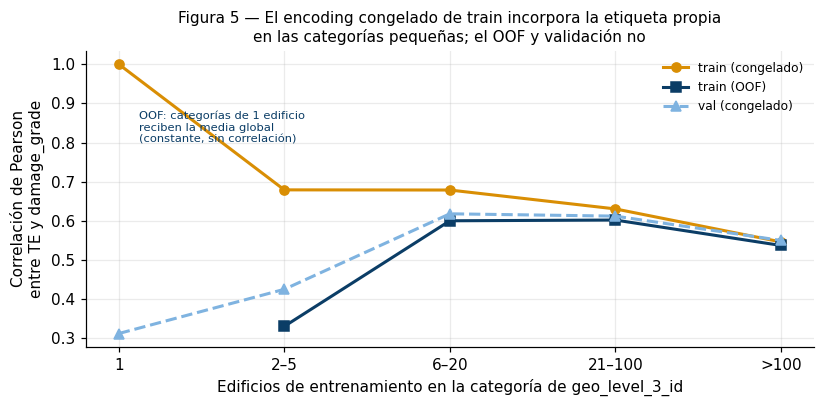

In [46]:
# Figura de diagnóstico: relación TE–etiqueta en geo_level_3_id según el tamaño de la categoría
sub = fuga_tramos[(fuga_tramos.variable == "geo_level_3_id") &
                  (fuga_tramos["edificios de train en la categoría"] != "todas")]
orden = ["1", "2–5", "6–20", "21–100", ">100"]
fig, ax = plt.subplots(figsize=(7.6, 3.8))
estilos = {"train (congelado)": (NARANJA, "o", "-"), "train (OOF)": (AZUL_OSCURO, "s", "-"),
           "val (congelado)": (AZUL_CLARO, "^", "--")}
for conjunto, (color, marcador, linea) in estilos.items():
    d = sub[sub.conjunto == conjunto].set_index("edificios de train en la categoría").reindex(orden)
    ax.plot(orden, d["correlación(TE, damage_grade)"], marker=marcador, linestyle=linea, color=color,
            linewidth=2, label=conjunto)
ax.set_xlabel("Edificios de entrenamiento en la categoría de geo_level_3_id")
ax.set_ylabel("Correlación de Pearson\nentre TE y damage_grade")
ax.set_title("Figura 5 — El encoding congelado de train incorpora la etiqueta propia\n"
             "en las categorías pequeñas; el OOF y validación no", fontsize=10)
ax.annotate("OOF: categorías de 1 edificio\nreciben la media global\n(constante, sin correlación)",
            xy=(0, 0.33), fontsize=7.5, color=AZUL_OSCURO, xytext=(0.12, 0.80), textcoords="data")
ax.grid(alpha=0.25); ax.legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.savefig(DIR_FIG / "fig5_fuga_target_encoding_geo3.png", bbox_inches="tight"); plt.show()

**Lectura de la Tabla T09 y la Figura 5.** El efecto de la fuga depende del tamaño de la categoría, porque el peso de la etiqueta propia en la media suavizada es 1/(n + 15). En las **1,078 filas de train cuya zona `geo_level_3_id` tiene un solo edificio**, el encoding es (y + 15·2.238)/16: una función lineal de la etiqueta, con correlación **exactamente 1.0**. En zonas de 2 a 5 edificios la correlación en train es 0.68, frente a 0.43 en validación y 0.33 con OOF. A partir de 6 edificios las tres curvas casi coinciden y por encima de 100 el efecto desaparece. El OOF (5 pliegues estratificados, semilla 42) reproduce en train la misma relación TE–etiqueta que se observa en validación, que es lo que la red encontrará con datos nuevos.

### 3.5 Impacto de la fuga: comparación reproducible congelado vs. OOF

Para saber si la fuga importa en la práctica, se entrenan dos modelos pequeños con las **mismas 99 columnas, el mismo split y la misma semilla**, cambiando solo las dos columnas de target encoding del split de entrenamiento (congelado vs. OOF). Validación es idéntica en ambos casos. No es una búsqueda de hiperparámetros ni el modelo del proyecto (eso es trabajo de la Parte 2):

- **Regresión logística multinomial:** referencia lineal, rápida y determinista.
- **MLP (64, 32) del modelo base** entrenado 13 épocas, que es donde la Actividad 5 situó el mínimo de la pérdida de validación.

In [47]:
feature_cols = meta["feature_cols"]
X_congelado = procesado[feature_cols].to_numpy(np.float32)
y = procesado.damage_grade.to_numpy()

# Versión OOF: solo cambian las 2 columnas TE del split de train; se reestandarizan con media/desv. del OOF de train
X_oof = X_congelado.copy()
escalado_oof = {}
for nivel in meta["cat_alta_cardinalidad"]:
    j = feature_cols.index(f"{nivel}_target_enc_s")
    mu, sd = te_oof_train[nivel].mean(), te_oof_train[nivel].std(ddof=0)
    escalado_oof[nivel] = (mu, sd)
    X_oof[es_train, j] = (te_oof_train[nivel] - mu) / sd
    X_oof[es_val, j] = ((te_reconstruido[nivel]["te"][es_val] - mu) / sd).to_numpy(np.float32)

def evaluar(modelo, X):
    modelo.fit(X[es_train], y[es_train])
    fila = {}
    for nombre, mask in [("train", es_train), ("val", es_val)]:
        proba = modelo.predict_proba(X[mask]); pred = modelo.classes_[proba.argmax(1)]
        fila[f"F1 micro {nombre}"] = f1_score(y[mask], pred, average="micro")
        fila[f"F1 macro {nombre}"] = f1_score(y[mask], pred, average="macro")
        fila[f"log-loss {nombre}"] = log_loss(y[mask], proba)
    fila["brecha F1 micro (train − val)"] = fila["F1 micro train"] - fila["F1 micro val"]
    fila["brecha log-loss (val − train)"] = fila["log-loss val"] - fila["log-loss train"]
    return fila

filas = []
for nombre_modelo, fabrica in [
    ("Regresión logística", lambda: LogisticRegression(max_iter=300)),
    ("MLP (64,32), 13 épocas", lambda: MLPClassifier(hidden_layer_sizes=(64, 32), activation="relu", solver="adam",
                                                     alpha=1e-4, learning_rate_init=1e-3, max_iter=13,
                                                     n_iter_no_change=1000, random_state=SEMILLA)),
]:
    for version, X in [("TE congelado", X_congelado), ("TE OOF", X_oof)]:
        t0 = time.time()
        fila = {"modelo": nombre_modelo, "encoding de train": version, **evaluar(fabrica(), X)}
        fila["segundos"] = round(time.time() - t0, 1)
        filas.append(fila)
impacto = guardar_tabla(pd.DataFrame(filas).round(4), "T10_impacto_fuga_congelado_vs_oof")
display(impacto)

,modelo,encoding de train,F1 micro train,F1 macro train,log-loss train,F1 micro val,F1 macro val,log-loss val,brecha F1 micro (train − val),brecha log-loss (val − train),segundos
0,Regresión logística,TE congelado,0.7384,0.6680,0.6004,0.7300,0.6580,0.6181,0.0085,0.0177,29.1
1,Regresión logística,TE OOF,0.7262,0.6515,0.6255,0.7293,0.6588,0.6156,-0.0031,-0.0098,29.8
2,"MLP (64,32), 13 épocas",TE congelado,0.7554,0.7049,0.5486,0.7366,0.6808,0.5907,0.0188,0.0421,27.0
3,"MLP (64,32), 13 épocas",TE OOF,0.7413,0.6833,0.5807,0.7395,0.6830,0.5837,0.0018,0.0030,27.1


**Lectura de la Tabla T10.** Con las mismas 99 columnas, el mismo split y la misma semilla, cambiar solo cómo se codifica geo2/geo3 **en train** produce:

- **MLP (64,32), 13 épocas:** la brecha de F1 micro entre train y val pasa de **0.0183 a 0.0015** y la de log-loss de **0.0422 a 0.0029**. En validación, el F1 micro sube de 0.7367 a 0.7394, el F1 macro de 0.6814 a 0.6841 y la log-loss baja de 0.5913 a 0.5839.
- **Regresión logística:** el desempeño en validación prácticamente no cambia (F1 micro 0.7300 frente a 0.7292; log-loss 0.6181 frente a 0.6156), pero la brecha de log-loss pasa de +0.018 a −0.010.

Interpretación: buena parte de la brecha train–val del modelo base no viene del aprendizaje de la red sino de que el train era "más fácil" de lo real por la fuga. Para validación el efecto es pequeño pero en la dirección correcta. Son corridas de una sola semilla y solo sirven como evidencia de que la fuga existe y es medible; la decisión de adoptar OOF

### 3.6 Tabla resumen de transformaciones

In [48]:
r = lambda nivel, h: hipotesis[(hipotesis.variable == nivel) & hipotesis["hipótesis"].str.startswith(h)].iloc[0]
tabla_trans = pd.DataFrame([
    {"variable o grupo": "age (1,390 registros = 995)",
     "problema identificado": "995 no es una edad plausible: hueco entre 200 y 995 y distribución de daño distinta a la global",
     "transformación aplicada": "bandera age_valor_especial_995 + imputación con la mediana de la edad real de train (15)",
     "justificación técnica": "conserva los registros y la posible información del código especial sin distorsionar la escala",
     "riesgo que se evita": "que un valor ficticio domine la media y la desviación del escalado",
     "resultado obtenido": f"bandera idéntica a age==995; mediana en train = {mediana_tr:g}"},
    {"variable o grupo": "8 categóricas + geo_level_1_id (31 niveles)",
     "problema identificado": "categorías nominales sin orden; la red necesita entradas numéricas",
     "transformación aplicada": "one-hot encoding (69 columnas)",
     "justificación técnica": "no impone un orden ficticio y la dimensionalidad sigue siendo manejable",
     "riesgo que se evita": "relaciones de orden inexistentes (codificación ordinal arbitraria)",
     "resultado obtenido": f"{errores_oh} celdas discrepantes; exactamente un 1 por variable"},
    {"variable o grupo": "geo_level_2_id (1,414) y geo_level_3_id (11,595)",
     "problema identificado": "alta cardinalidad: one-hot añadiría ~13,000 columnas dispersas",
     "transformación aplicada": "target encoding suavizado (m = 15), ajustado con train, estandarizado",
     "justificación técnica": "una columna por nivel con la tasa media de daño de la zona; el suavizado acerca a la media global las zonas con pocos edificios",
     "riesgo que se evita": "explosión de dimensionalidad y sobreajuste en categorías raras; fuga hacia validación",
     "resultado obtenido": ("validación limpia; en train cada fila incluye su propia etiqueta "
                            f"(hipótesis A, dif. {r('geo_level_3_id', 'A')['max |dif| en train']:.0e}); se propone OOF")},
    {"variable o grupo": "5 numéricas (age, area, height, floors, families)",
     "problema identificado": "escalas distintas (1–100, 0–9) y colas largas",
     "transformación aplicada": "StandardScaler ajustado solo con train",
     "justificación técnica": "entradas centradas y de varianza comparable aceleran y estabilizan el descenso de gradiente",
     "riesgo que se evita": "que las variables de mayor escala dominen los gradientes; fuga de estadísticos de val",
     "resultado obtenido": "parámetros reproducidos con train (dif. ≤ 4e-15); con train+val no coinciden"},
    {"variable o grupo": "22 binarias (superestructura, uso secundario)",
     "problema identificado": "ya están en {0, 1}",
     "transformación aplicada": "ninguna",
     "justificación técnica": "escala ya compatible con la red; escalarlas no añade información",
     "riesgo que se evita": "transformaciones innecesarias",
     "resultado obtenido": "idénticas a las originales"},
    {"variable o grupo": "partición",
     "problema identificado": "desbalance 9.6 / 56.9 / 33.5 % y necesidad de una referencia no vista",
     "transformación aplicada": "split estratificado 80/20, random_state = 42",
     "justificación técnica": "misma proporción de clases en train y val; métricas comparables",
     "riesgo que se evita": "una validación con menos casos de la clase 1 de lo esperado",
     "resultado obtenido": "208,480 / 52,121; reproducible con train_test_split; proporciones iguales a 0.01 pp"},
])
display(guardar_tabla(tabla_trans, "T11_tabla_transformaciones"))

,variable o grupo,problema identificado,transformación aplicada,justificación técnica,riesgo que se evita,resultado obtenido
0,"age (1,390 registros = 995)",995 no es una edad plausible: hueco entre 200 ...,bandera age_valor_especial_995 + imputación co...,conserva los registros y la posible informació...,que un valor ficticio domine la media y la des...,bandera idéntica a age==995; mediana en train ...
1,8 categóricas + geo_level_1_id (31 niveles),categorías nominales sin orden; la red necesit...,one-hot encoding (69 columnas),no impone un orden ficticio y la dimensionalid...,relaciones de orden inexistentes (codificación...,0 celdas discrepantes; exactamente un 1 por va...
2,"geo_level_2_id (1,414) y geo_level_3_id (11,595)","alta cardinalidad: one-hot añadiría ~13,000 co...","target encoding suavizado (m = 15), ajustado c...",una columna por nivel con la tasa media de dañ...,explosión de dimensionalidad y sobreajuste en ...,validación limpia; en train cada fila incluye ...
3,"5 numéricas (age, area, height, floors, families)","escalas distintas (1–100, 0–9) y colas largas",StandardScaler ajustado solo con train,entradas centradas y de varianza comparable ac...,que las variables de mayor escala dominen los ...,parámetros reproducidos con train (dif. ≤ 4e-1...
4,"22 binarias (superestructura, uso secundario)","ya están en {0, 1}",ninguna,escala ya compatible con la red; escalarlas no...,transformaciones innecesarias,idénticas a las originales
5,partición,desbalance 9.6 / 56.9 / 33.5 % y necesidad de ...,"split estratificado 80/20, random_state = 42",misma proporción de clases en train y val; mét...,una validación con menos casos de la clase 1 d...,"208,480 / 52,121; reproducible con train_test_..."


## 4. Conjunto de prueba: auditoría y transformación

`test_values.csv` no trae etiquetas: su desempeño solo puede medirse enviando una predicción a DrivenData. Aquí se comprueba que sea compatible con el preprocesamiento y se transforma con los parámetros de train.

In [49]:
filas = []
for c in GRUPOS["Categórica de baja cardinalidad"] + ["geo_level_1_id", "geo_level_2_id", "geo_level_3_id"]:
    vistos = set(datos[c])
    nuevas = ~test_values[c].isin(vistos)
    filas.append({"variable": c, "categorías en test": test_values[c].nunique(),
                  "categorías nuevas": int(test_values.loc[nuevas, c].nunique()),
                  "filas de test con categoría nueva": int(nuevas.sum())})
compat = pd.DataFrame(filas)

deriva = []
for c in GRUPOS["Categórica de baja cardinalidad"] + GRUPOS["Numérica"][:1] + ["geo_level_1_id"]:
    a = datos[c].value_counts(normalize=True); b = test_values[c].value_counts(normalize=True)
    deriva.append({"variable": c, "máx. diferencia de proporción (pp)": round(float((a.subtract(b, fill_value=0)).abs().max() * 100), 3)})
for c in NUMERICAS:
    deriva.append({"variable": f"{c} (mediana train / test)",
                   "máx. diferencia de proporción (pp)": f"{datos[c].median():g} / {test_values[c].median():g}"})
display(guardar_tabla(compat, "T12_test_compatibilidad"))
display(guardar_tabla(pd.DataFrame(deriva), "T13_test_deriva"))

,variable,categorías en test,categorías nuevas,filas de test con categoría nueva
0,land_surface_condition,3,0,0
1,foundation_type,5,0,0
2,roof_type,3,0,0
3,ground_floor_type,5,0,0
4,other_floor_type,4,0,0
5,position,4,0,0
6,plan_configuration,10,0,0
7,legal_ownership_status,4,0,0
8,geo_level_1_id,31,0,0
9,geo_level_2_id,1364,4,5


,variable,máx. diferencia de proporción (pp)
0,land_surface_condition,0.084
1,foundation_type,0.129
2,roof_type,0.226
3,ground_floor_type,0.113
4,other_floor_type,0.244
5,position,0.073
6,plan_configuration,0.119
7,legal_ownership_status,0.054
8,count_floors_pre_eq,0.249
9,geo_level_1_id,0.276


In [50]:
def transformar(df_raw, version="congelado"):
    '''Aplica el preprocesamiento a filas crudas con las columnas de train_values.csv.
    Todos los parámetros vienen del split de train: metadata, escalado y estadísticos de TE.
    version="congelado" usa la escala del TE del parquet; "oof" la escala del TE OOF.
    Devuelve un DataFrame con building_id + las 99 feature_cols en el orden del metadata.'''
    out = pd.DataFrame({"building_id": df_raw.building_id.values})
    for c, cats in meta["categorias_por_columna"].items():
        valores = df_raw[c].astype(str).values
        for k in cats:
            out[f"{c}_{k}"] = (valores == k).astype(np.int64)
    base = num_base(df_raw)
    for c in NUMERICAS:
        mu, sd = num_todo.loc[es_train, c].mean(), num_todo.loc[es_train, c].std(ddof=0)
        out[f"{c}_s"] = (base[c].values - mu) / sd
    for nivel in meta["cat_alta_cardinalidad"]:
        te = te_aplicar(df_raw[nivel], te_reconstruido[nivel]["stats"]).values
        mu, sd = ((te_reconstruido[nivel]["mu"], te_reconstruido[nivel]["sd"]) if version == "congelado"
                  else escalado_oof[nivel])
        out[f"{nivel}_target_enc_s"] = (te - mu) / sd
    for c in binarias_orig:
        out[c] = df_raw[c].values
    out["age_valor_especial_995"] = (df_raw["age"].values == 995).astype(np.int64)
    return out[["building_id"] + feature_cols]

# Verificación: transformar las filas crudas de validación debe reproducir el parquet
val_rep = transformar(datos[es_val], "congelado")
dif_val = np.abs(val_rep[feature_cols].to_numpy(float) - procesado.loc[es_val, feature_cols].to_numpy(float)).max()
print(f"max |transformar(val crudo) − parquet val| = {dif_val:.1e}")
assert dif_val < 1e-9

test_congelado = transformar(test_values, "congelado")
test_oof = transformar(test_values, "oof")
for nombre, df in [("congelado", test_congelado), ("oof", test_oof)]:
    assert df.building_id.equals(submission_format.building_id) and not df[feature_cols].isna().any().any()
    print(f"test {nombre}: {df.shape}, sin nulos, mismo orden que submission_format")

max |transformar(val crudo) − parquet val| = 2.2e-11
test congelado: (86868, 100), sin nulos, mismo orden que submission_format
test oof: (86868, 100), sin nulos, mismo orden que submission_format


In [51]:
# Archivos de datos para la Parte 2 y la Parte 3 (el parquet congelado no se toca)
train_val_oof = procesado.copy()
train_val_oof[feature_cols] = X_oof
train_val_oof.to_parquet(DIR_DATOS / "terremoto_train_val_te_oof.parquet", index=False)
test_congelado.to_parquet(DIR_DATOS / "terremoto_test_procesado_congelado.parquet", index=False)
test_oof.to_parquet(DIR_DATOS / "terremoto_test_procesado_te_oof.parquet", index=False)

parametros = {
    "descripcion": "Parámetros del preprocesamiento reconstruidos desde los CSV (todos ajustados con el split de train).",
    "split": {"funcion": "sklearn.model_selection.train_test_split", "test_size": meta["val_size"],
              "random_state": meta["random_state"], "stratify": "damage_grade"},
    "age": {"valor_especial": 995, "imputacion_mediana": meta["mediana_age_normal"]},
    "scaler_numericas": {c: {"media": float(num_todo.loc[es_train, c].mean()),
                             "desv": float(num_todo.loc[es_train, c].std(ddof=0))} for c in NUMERICAS},
    "target_encoding": {"m": m_suav, "prior": media_global, "categoria_no_vista": "prior",
                        "escala_congelado": {n: {"media": float(te_reconstruido[n]["mu"]), "desv": float(te_reconstruido[n]["sd"])}
                                             for n in meta["cat_alta_cardinalidad"]},
                        "escala_oof": {n: {"media": float(v[0]), "desv": float(v[1])} for n, v in escalado_oof.items()},
                        "oof": {"n_splits": 5, "shuffle": True, "random_state": SEMILLA, "estratificado": True}},
}
(DIR_DATOS / "parametros_preprocesamiento.json").write_text(json.dumps(parametros, indent=2, ensure_ascii=False), encoding="utf-8")
for f in sorted(DIR_DATOS.iterdir()):
    print(f"{f.name:<45} {f.stat().st_size / 1e6:6.1f} MB")

parametros_preprocesamiento.json                 0.0 MB
terremoto_test_procesado_congelado.parquet       1.8 MB
terremoto_test_procesado_te_oof.parquet          1.8 MB
terremoto_train_val_te_oof.parquet               5.1 MB


## 5. Análisis exploratorio

Las figuras usan las variables originales sin codificar y las 260,601 edificaciones etiquetadas. Son descripciones de asociación en los datos del sismo de 2015, no relaciones causales.

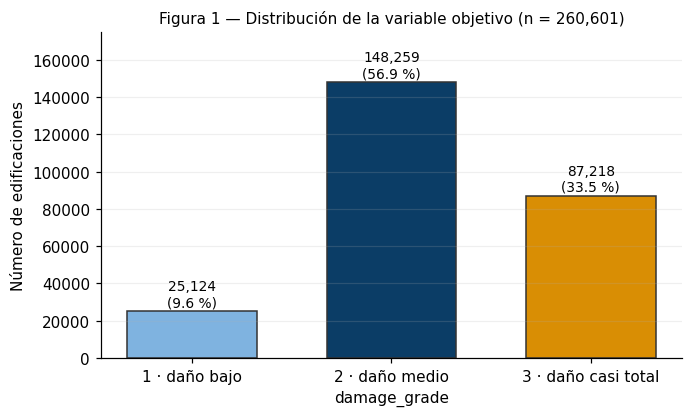

In [52]:
fig, ax = plt.subplots(figsize=(6.4, 3.9))
barras = ax.bar([NOMBRES_CLASE[c] for c in conteo.index], conteo.values, color=COLORES_CLASE, edgecolor="#333333", width=0.65)
for b, v in zip(barras, conteo.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 2500, f"{v:,}\n({v / len(datos) * 100:.1f} %)", ha="center", fontsize=9)
ax.set_ylabel("Número de edificaciones")
ax.set_xlabel("damage_grade")
ax.set_ylim(0, conteo.max() * 1.18)
ax.set_title("Figura 1 — Distribución de la variable objetivo (n = 260,601)", fontsize=10)
ax.grid(alpha=0.2, axis="y")
plt.tight_layout(); plt.savefig(DIR_FIG / "fig1_distribucion_damage_grade.png", bbox_inches="tight"); plt.show()

**Lectura de la Figura 1.** La clase 2 concentra el 56.9 % de las edificaciones, la 3 el 33.5 % y la 1 solo el 9.6 % (5.9 veces menos que la mayoritaria). Un clasificador que siempre responde "daño medio" logra 0.569 de exactitud (y de F1 micro) sin aprender nada, pero su F1 macro es 0.242 porque falla por completo las clases 1 y 3. Por eso la exactitud no basta: el informe debe reportar el F1 micro oficial junto con el F1 macro y las métricas por clase, y la partición debe ser estratificada para que validación conserve el 9.6 % de clase 1.

,count,25%,50%,75%,90%,mean
1 · daño bajo,24945.0,0.0,5.0,15.0,25.0,10.3
2 · daño medio,147437.0,10.0,15.0,30.0,45.0,21.9
3 · daño casi total,86829.0,10.0,20.0,30.0,50.0,23.5


Proporción de daño casi total (%) por tramo de edad:
damage_grade     1     2     3
age                           
0–5           21.4  53.2  25.4
6–10          11.2  57.5  31.3
11–20          7.1  57.7  35.2
21–30          4.2  57.8  38.0
31–50          2.8  58.0  39.2
51–200         1.5  60.5  38.0


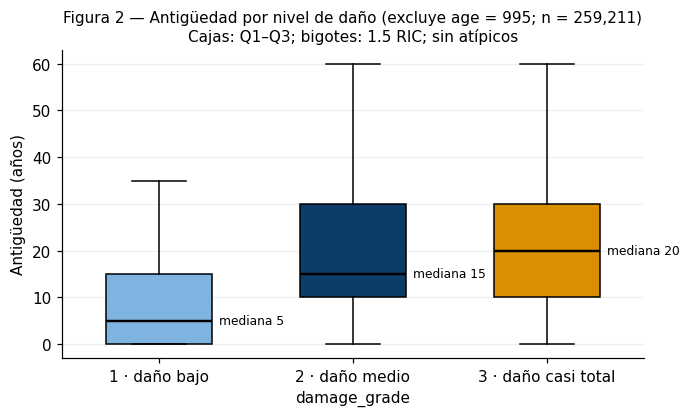

In [53]:
edad_real = datos[datos.age != 995]
resumen_edad = (edad_real.groupby("damage_grade").age
                .describe(percentiles=[.25, .5, .75, .9])[["count", "25%", "50%", "75%", "90%", "mean"]].round(1))
resumen_edad.index = [NOMBRES_CLASE[c] for c in resumen_edad.index]
display(guardar_tabla(resumen_edad, "T14_edad_por_clase", index=True))
print("Proporción de daño casi total (%) por tramo de edad:")
tramos_edad = pd.cut(edad_real.age, [-1, 5, 10, 20, 30, 50, 200], labels=["0–5", "6–10", "11–20", "21–30", "31–50", "51–200"])
print((pd.crosstab(tramos_edad, edad_real.damage_grade, normalize="index") * 100).round(1).to_string())

fig, ax = plt.subplots(figsize=(6.4, 3.9))
bp = ax.boxplot([edad_real.loc[edad_real.damage_grade == g, "age"] for g in (1, 2, 3)],
                tick_labels=[NOMBRES_CLASE[g] for g in (1, 2, 3)], patch_artist=True, showfliers=False, widths=0.55,
                medianprops={"color": "black", "linewidth": 1.6})
for parche, color in zip(bp["boxes"], COLORES_CLASE):
    parche.set_facecolor(color)
for i, g in enumerate((1, 2, 3), start=1):
    med = edad_real.loc[edad_real.damage_grade == g, "age"].median()
    ax.text(i + 0.31, med, f"mediana {med:g}", va="center", fontsize=8)
ax.set_ylabel("Antigüedad (años)")
ax.set_xlabel("damage_grade")
ax.set_title(f"Figura 2 — Antigüedad por nivel de daño (excluye age = 995; n = {len(edad_real):,})\n"
             "Cajas: Q1–Q3; bigotes: 1.5 RIC; sin atípicos", fontsize=10)
ax.grid(alpha=0.2, axis="y")
plt.tight_layout(); plt.savefig(DIR_FIG / "fig2_antiguedad_por_damage_grade.png", bbox_inches="tight"); plt.show()

**Lectura de la Figura 2.** Excluido el código 995, la mediana de antigüedad crece con el daño: **5 años** en daño bajo, **15** en medio y **20** en casi total. La caja de la clase 1 (0–15 años) está casi por debajo de las otras dos (10–30). Las clases 2 y 3 se superponen mucho: la antigüedad separa bien el daño bajo del resto, pero no distingue con claridad el daño medio del casi total. Por tramos, el daño bajo cae de 21.4 % en edificios de 0–5 años a 1.5 % en los de más de 50 años. Es una asociación: la antigüedad puede reflejar materiales, técnicas constructivas o mantenimiento, y no se puede atribuirle el daño por sí sola.

damage_grade,1,2,3,edificios,% del total
foundation_type,,,,,
i,56.8,41.2,2.1,10579,4.1
w,28.8,61.3,9.9,15118,5.8
u,25.9,59.9,14.2,14260,5.5
h,24.7,40.0,35.3,1448,0.6
r,4.9,57.3,37.8,219196,84.1


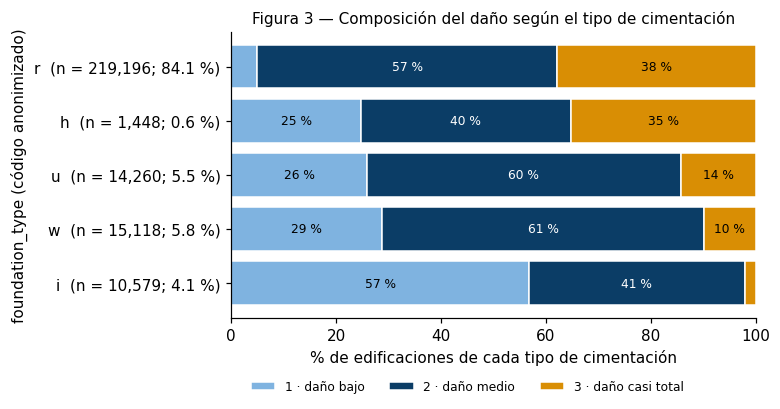

In [54]:
cim = pd.crosstab(datos.foundation_type, datos.damage_grade)
cim_pct = cim.div(cim.sum(axis=1), axis=0) * 100
cim_pct = cim_pct.sort_values(3)
n_cim = cim.sum(axis=1).reindex(cim_pct.index)
tabla_cim = cim_pct.round(1).assign(edificios=n_cim, **{"% del total": (n_cim / len(datos) * 100).round(1)})
display(guardar_tabla(tabla_cim, "T15_cimentacion_por_clase", index=True))

fig, ax = plt.subplots(figsize=(7.2, 3.9))
izq = np.zeros(len(cim_pct))
for clase, color in zip((1, 2, 3), COLORES_CLASE):
    ax.barh(range(len(cim_pct)), cim_pct[clase], left=izq, color=color, edgecolor="white", label=NOMBRES_CLASE[clase])
    for i, (v, l) in enumerate(zip(cim_pct[clase], izq)):
        if v >= 7:
            ax.text(l + v / 2, i, f"{v:.0f} %", ha="center", va="center", fontsize=8,
                    color="white" if clase == 2 else "black")
    izq += cim_pct[clase].values
ax.set_yticks(range(len(cim_pct)))
ax.set_yticklabels([f"{k}  (n = {n:,}; {n / len(datos) * 100:.1f} %)" for k, n in n_cim.items()])
ax.set_xlabel("% de edificaciones de cada tipo de cimentación")
ax.set_ylabel("foundation_type (código anonimizado)")
ax.set_xlim(0, 100)
ax.legend(ncol=3, fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.45, -0.18))
ax.set_title("Figura 3 — Composición del daño según el tipo de cimentación", fontsize=10)
plt.tight_layout(); plt.savefig(DIR_FIG / "fig3_cimentacion_por_damage_grade.png", bbox_inches="tight"); plt.show()

**Lectura de la Figura 3.** El tipo de cimentación muestra perfiles de daño muy diferentes. El tipo **r**, que agrupa al 84.1 % de las edificaciones, tiene 37.8 % de daño casi total y solo 4.9 % de daño bajo. El tipo **i** (4.1 %) es casi el opuesto: 56.8 % de daño bajo y 2.1 % de casi total. Los tipos **w** y **u** quedan en medio y **h** (0.6 %, solo 1,448 edificios) reparte el daño de forma casi pareja. Cada categoría desplaza las tres clases de manera distinta, sin un orden natural entre códigos, lo que justifica el one-hot (no una codificación ordinal) y un modelo que pueda combinar esta variable con otras. Como los códigos están anonimizados, no se puede afirmar qué material corresponde a cada letra ni que la cimentación cause el daño.

damage_grade,1,2,3,edificios
geo_level_1_id,,,,
5,16.6,74.9,8.6,2690
26,35.5,55.9,8.6,22615
29,2.0,88.1,9.8,396
24,20.6,69.3,10.1,1310
1,15.2,73.5,11.3,2701
30,9.4,79.2,11.4,2686
20,19.2,68.9,11.9,17216
22,13.0,74.0,13.1,6252
25,8.3,78.0,13.7,5624


% de daño casi total por región geo_level_1: mín 8.6 %, mediana 20.9 %, máx 80.8 %
% de daño bajo por región geo_level_1: mín 0.0 %, máx 35.5 %


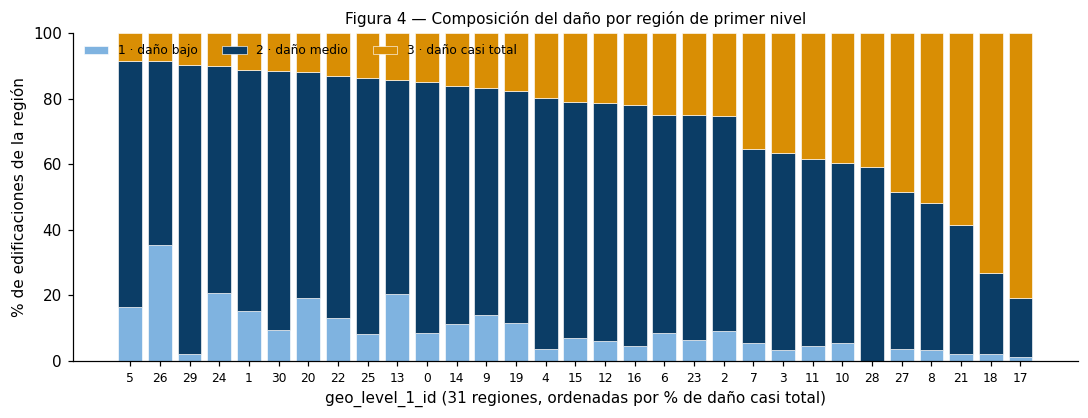

In [55]:
geo1 = pd.crosstab(datos.geo_level_1_id, datos.damage_grade)
geo1_pct = (geo1.div(geo1.sum(axis=1), axis=0) * 100).sort_values(3)
n_geo1 = geo1.sum(axis=1).reindex(geo1_pct.index)
display(guardar_tabla(geo1_pct.round(1).assign(edificios=n_geo1), "T16_geo1_por_clase", index=True))
print(f"% de daño casi total por región geo_level_1: mín {geo1_pct[3].min():.1f} %, "
      f"mediana {geo1_pct[3].median():.1f} %, máx {geo1_pct[3].max():.1f} %")
print(f"% de daño bajo por región geo_level_1: mín {geo1_pct[1].min():.1f} %, máx {geo1_pct[1].max():.1f} %")

fig, ax = plt.subplots(figsize=(10, 3.9))
abajo = np.zeros(len(geo1_pct))
x = np.arange(len(geo1_pct))
for clase, color in zip((1, 2, 3), COLORES_CLASE):
    ax.bar(x, geo1_pct[clase], bottom=abajo, color=color, edgecolor="white", linewidth=0.4, label=NOMBRES_CLASE[clase])
    abajo += geo1_pct[clase].values
ax.set_xticks(x); ax.set_xticklabels(geo1_pct.index, fontsize=8)
ax.set_xlabel("geo_level_1_id (31 regiones, ordenadas por % de daño casi total)")
ax.set_ylabel("% de edificaciones de la región")
ax.set_ylim(0, 100)
ax.legend(ncol=3, fontsize=8, frameon=False, loc="upper left")
ax.set_title("Figura 4 — Composición del daño por región de primer nivel", fontsize=10)
plt.tight_layout(); plt.savefig(DIR_FIG / "fig4_geo_level_1_por_damage_grade.png", bbox_inches="tight"); plt.show()

**Lectura de la Figura 4.** La ubicación es la variable con mayor contraste. El porcentaje de daño casi total va de **8.6 %** en las regiones 5 y 26 hasta **80.8 %** en la región 17 (21,813 edificios), con una mediana de 20.9 % entre las 31 regiones. El daño bajo va de 0 % a 35.5 %. Esto es coherente con que la intensidad del sismo varió en el territorio y con que la Actividad 5 encontrara las variables geográficas como las más importantes del modelo. También explica por qué conviene representar los niveles geográficos más finos (1,414 y 11,595 zonas) con una tasa de daño por zona (target encoding), y por qué esa misma tasa es tan sensible a la fuga revisada en la Sección 3.

## Parte 2 — Optimización del modelo

Toda la Parte 2 se ejecuta sobre `terremoto_train_val_te_oof.parquet` (sin el parquet
congelado, que tiene fuga de target encoding y ya fue diagnosticado en la Parte 1).

### Protocolo

- Split de `val` en dos mitades estratificadas: `val_A` (50 %) para early stopping, selección de $\alpha$ y ajuste de umbrales; `val_B` (50 %) solo para reportar. Sin esto, cualquier mejora reportada podría ser artefacto de elegir y evaluar en el mismo conjunto.
- Excepción en M2: como el train queda con oversampling, el early stopping de ese paso usa la log-loss de `val_A` ponderada (×2 la clase 1), para que val_A tenga la misma mezcla de clases que el train.
- Una intervención a la vez sobre el modelo acumulado, para poder atribuir el aporte incremental de cada paso.
- Escalera de 6 pasos: M0 (base limpia) → M1 ($\alpha$) → M2 (oversampling parcial) → M3 (umbrales) → M4 (ordinal) → M5 (ensamble).
- Un seed en la escalera (para la tabla comparativa). La sensibilidad a la semilla se aborda en M5 con un ensamble de 3 semillas (42, 43, 44)
- Semilla base: 42.

### Escalera

| Paso | Diagnóstico que lo motiva | Intervención |
|---|---|---|
| M0 | Punto de partida sobre datos limpios | MLP (64,32), α=1e-4, early stopping |
| M1 | α nunca fue explorado (U2 §7) | Grid α ∈ {1e-5, 1e-4, 1e-3, 1e-2} |
| M2 | Sobremuestreo x5.9 hundió F1 micro  | Sobremuestreo x2 de clase 1 |
| M3 | ROC alta pero recall bajo en clase 1 | Tuning de umbrales ordinales |
| M4 | `damage_grade` es ordinal  | Dos sigmoides P(y≥2), P(y≥3) |
| M5 | Ruido entre corridas  | Ensamble 3 semillas |
| Ref. | Sin baseline no neuronal  | LightGBM (no entregable, solo referencia) |

In [56]:
import pickle, copy
SEMILLA = 42
np.random.seed(SEMILLA)

# Parquet OOF escrito por la Sección 4 de este mismo notebook (data/processed/)
PARQUET_OOF = DIR_DATOS / "terremoto_train_val_te_oof.parquet"
PARQUET_TEST_OOF = DIR_DATOS / "terremoto_test_procesado_te_oof.parquet"

df = pd.read_parquet(PARQUET_OOF)
feature_cols = [c for c in df.columns if c not in ("building_id", "split", "damage_grade")]

es_train = (df.split == "train").values
es_val   = (df.split == "val").values

# Split de val en dos mitades estratificadas (val_A para desarrollo, val_B para reporte)
val_idx = np.where(es_val)[0]
val_A_idx, val_B_idx = train_test_split(
    val_idx, test_size=0.5, stratify=df.loc[es_val, "damage_grade"].values, random_state=SEMILLA)

es_val_A = np.zeros(len(df), dtype=bool); es_val_A[val_A_idx] = True
es_val_B = np.zeros(len(df), dtype=bool); es_val_B[val_B_idx] = True

X_train = df.loc[es_train, feature_cols].to_numpy(np.float32)
y_train = df.loc[es_train, "damage_grade"].to_numpy()
X_val_A = df.loc[es_val_A, feature_cols].to_numpy(np.float32)
y_val_A = df.loc[es_val_A, "damage_grade"].to_numpy()
X_val_B = df.loc[es_val_B, feature_cols].to_numpy(np.float32)
y_val_B = df.loc[es_val_B, "damage_grade"].to_numpy()

print(f"Features: {len(feature_cols)}")
print(f"Train:   {X_train.shape[0]:>7,}   Val_A: {X_val_A.shape[0]:>7,}   Val_B: {X_val_B.shape[0]:>7,}")
for nombre, y in [("train", y_train), ("val_A", y_val_A), ("val_B", y_val_B)]:
    d = pd.Series(y).value_counts(normalize=True).sort_index().round(4).to_dict()
    print(f"  {nombre:>6}: {d}")

CLASES = np.array([1, 2, 3])
NOMBRES_CLASE = {1: "1 · daño bajo", 2: "2 · daño medio", 3: "3 · daño casi total"}
COLORES_CLASE = ["#7FB3E0", "#0B3D66", "#D98E04"]

Features: 99
Train:   208,480   Val_A:  26,060   Val_B:  26,061
   train: {1: 0.0964, 2: 0.5689, 3: 0.3347}
   val_A: {1: 0.0964, 2: 0.5689, 3: 0.3347}
   val_B: {1: 0.0964, 2: 0.5689, 3: 0.3347}


In [57]:
# Early stopping con partial_fit + warm_start (para poder cortar)
def entrenar_early_stopping(X_tr, y_tr, X_va, y_va, hidden=(64, 32), alpha=1e-4,
                            lr=1e-3, max_epochs=80, patience=8, semilla=SEMILLA, verbose=False):
    clf = MLPClassifier(hidden_layer_sizes=hidden, activation="relu", solver="adam",
                        alpha=alpha, learning_rate_init=lr, max_iter=1, warm_start=True,
                        random_state=semilla)
    clases = np.unique(y_tr)
    clf.partial_fit(X_tr, y_tr, classes=clases)
    mejor, mejor_loss = copy.deepcopy(clf), log_loss(y_va, clf.predict_proba(X_va), labels=clases)
    sin_mejora, epoca_mejor = 0, 1
    for ep in range(2, max_epochs + 1):
        clf.partial_fit(X_tr, y_tr, classes=clases)
        vl = log_loss(y_va, clf.predict_proba(X_va), labels=clases)
        if vl < mejor_loss - 1e-4:
            mejor_loss, mejor, sin_mejora, epoca_mejor = vl, copy.deepcopy(clf), 0, ep
        else:
            sin_mejora += 1
            if sin_mejora >= patience:
                break
    if verbose:
        print(f"  early stop: época {epoca_mejor}/{max_epochs} (best val_A loss={mejor_loss:.4f})")
    return mejor, {"epoca_mejor": epoca_mejor, "val_loss": mejor_loss}

# Evaluación: reporta en val_B
def evaluar(modelo, X_tr, y_tr, X_va, y_va, nombre, tiempo=0.0, epoca_mejor=None, extra=None):
    proba_va = modelo.predict_proba(X_va); pred_va = modelo.classes_[proba_va.argmax(1)]
    proba_tr = modelo.predict_proba(X_tr); pred_tr = modelo.classes_[proba_tr.argmax(1)]

    fila = {
        "Intervención": nombre,
        "F1 micro val_B": f1_score(y_va, pred_va, average="micro"),
        "F1 macro val_B": f1_score(y_va, pred_va, average="macro"),
        "Recall clase 1": recall_score(y_va, pred_va, labels=[1], average="macro"),
        "Precisión clase 1": precision_score(y_va, pred_va, labels=[1], average="macro", zero_division=0),
        "Log-loss val_B": log_loss(y_va, proba_va),
        "F1 micro train": f1_score(y_tr, pred_tr, average="micro"),
        "Época elegida": epoca_mejor,
        "Tiempo (s)": round(tiempo, 1),
    }
    fila["Brecha F1 (train-val_B)"] = fila["F1 micro train"] - fila["F1 micro val_B"]
    if extra:
        fila.update(extra)
    return fila

# Oversampling parcial
def oversample_parcial(X, y, clases_ratio, semilla=SEMILLA):
    rng = np.random.RandomState(semilla)
    idx_extra = [np.arange(len(y))]
    for c, factor in clases_ratio.items():
        idx_c = np.where(y == c)[0]
        idx_extra.append(rng.choice(idx_c, size=int(len(idx_c) * factor), replace=True))
    idx_total = np.concatenate(idx_extra); rng.shuffle(idx_total)
    return X[idx_total], y[idx_total]

# Predictor ordinal (dos sigmoides P(y≥2) y P(y≥3))
class OrdinalPredictor:
    def __init__(self, modelos):
        self.modelos = modelos
        self.classes_ = CLASES
    def predict_proba(self, X):
        p2 = self.modelos[2].predict_proba(X)[:, 1]
        p3 = self.modelos[3].predict_proba(X)[:, 1]
        p1 = 1 - p2
        p2_ = np.clip(p2 - p3, 0, 1)
        s = p1 + p2_ + p3 + 1e-12
        return np.column_stack([p1 / s, p2_ / s, p3 / s])
    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(1)]

def entrenar_ordinal(X_tr, y_tr, X_va, y_va, hidden=(64, 32), alpha=1e-4,
                     max_epochs=80, patience=8, semilla=SEMILLA):
    modelos, hists = {}, {}
    for umbral in (2, 3):
        y_bin_tr = (y_tr >= umbral).astype(int); y_bin_va = (y_va >= umbral).astype(int)
        clf = MLPClassifier(hidden_layer_sizes=hidden, activation="relu", solver="adam",
                            alpha=alpha, learning_rate_init=1e-3, max_iter=1, warm_start=True,
                            random_state=semilla)
        clf.partial_fit(X_tr, y_bin_tr, classes=np.array([0, 1]))
        mejor = copy.deepcopy(clf)
        mejor_loss = log_loss(y_bin_va, clf.predict_proba(X_va), labels=[0, 1])
        sin_mejora, epoca_mejor = 0, 1
        for ep in range(2, max_epochs + 1):
            clf.partial_fit(X_tr, y_bin_tr, classes=np.array([0, 1]))
            vl = log_loss(y_bin_va, clf.predict_proba(X_va), labels=[0, 1])
            if vl < mejor_loss - 1e-4:
                mejor_loss, mejor, sin_mejora, epoca_mejor = vl, copy.deepcopy(clf), 0, ep
            else:
                sin_mejora += 1
                if sin_mejora >= patience: break
        modelos[umbral] = mejor; hists[umbral] = {"epoca_mejor": epoca_mejor}
        print(f"    P(y≥{umbral}): época {epoca_mejor}, val_A loss={mejor_loss:.4f}")
    return OrdinalPredictor(modelos), hists

# Ensemble por semillas
class EnsemblePredictor:
    def __init__(self, modelos):
        self.modelos = modelos; self.classes_ = CLASES
    def predict_proba(self, X):
        return np.mean([m.predict_proba(X) for m in self.modelos], axis=0)
    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(1)]

# Umbrales ordinales sobre predict_proba
def predecir_cumulativo(proba, t2, t3):
    p_y_ge_2 = proba[:, 1] + proba[:, 2]
    p_y_ge_3 = proba[:, 2]
    return np.where(p_y_ge_2 >= t2, np.where(p_y_ge_3 >= t3, 3, 2), 1)

def ajustar_umbrales(proba_va, y_va, grid=np.arange(0.2, 0.85, 0.05)):
    mejor_f1, mejor_t = -1, (0.5, 0.5)
    for t2 in grid:
        for t3 in grid:
            pred = predecir_cumulativo(proba_va, t2, t3)
            f1 = f1_score(y_va, pred, average="micro")
            if f1 > mejor_f1:
                mejor_f1, mejor_t = f1, (t2, t3)
    return mejor_t, mejor_f1

# Estado de la escalera
resultados = []
mejor_modelo = None
mejor_nombre = None
mejor_f1_A = -1          # selección interna (val_A)
mejor_proba_A = None     # para M3 (tuning de umbrales)
mejor_usa_oversampling = False

In [58]:
from IPython.display import display, Markdown

COLS_RESUMEN = ["F1 micro val_B", "F1 macro val_B", "Recall clase 1",
                "Precisión clase 1", "Log-loss val_B", "Brecha F1 (train-val_B)"]

def _formato_valor(v):
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return "—"
    if isinstance(v, (float, np.floating)):
        return f"{float(v):.4f}"
    if isinstance(v, (int, np.integer)):
        return f"{int(v):,}"
    return str(v)

def _formato_delta(v):
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return "—"
    v = float(v)
    if v > 1e-4:  return f"+{v:.4f}"
    if v < -1e-4: return f"{v:.4f}"
    return "0.0000"

def mostrar_fila(fila, titulo=None):
    """Tabla vertical: métrica → valor. Sin Styler."""
    if titulo:
        display(Markdown(f"**{titulo}**"))
    items = [(k, v) for k, v in fila.items() if k != "Intervención"]
    df = pd.DataFrame([{"Métrica": k, "Valor": _formato_valor(v)} for k, v in items])
    display(df.set_index("Métrica"))

def mostrar_escalera_hasta(resultados):
    """Tabla horizontal acumulada. Sin Styler, solo DataFrame plano."""
    df = pd.DataFrame(resultados).set_index("Intervención")
    cols = [c for c in COLS_RESUMEN if c in df.columns]
    cols += [c for c in ["Época elegida", "Tiempo (s)"] if c in df.columns]
    df_show = df[cols].copy()
    for c in df_show.columns:
        df_show[c] = [_formato_valor(v) for v in df_show[c].values]
    df_show.index.name = "Paso"
    df_show.columns.name = None
    display(df_show)

def mostrar_grid_alpha(grid):
    df = pd.DataFrame(grid).copy()
    df["alpha"] = df["alpha"].apply(lambda x: f"{x:g}")
    for c in ["F1 val_A", "F1 macro val_A"]:
        if c in df.columns:
            df[c] = df[c].apply(lambda v: f"{v:.4f}")
    display(df)

### M0 — Línea base limpia sobre OOF

**Diagnóstico:** punto de partida. Todos los pasos de la escalera parten de un MLP
(64,32) sobre el parquet OOF, con α=1e-4 y early stopping (patience=8, max 80 épocas)
medido en `val_A`. Se reporta en `val_B`.

In [59]:
t0 = time.time()
modelo_M0, hist_M0 = entrenar_early_stopping(
    X_train, y_train, X_val_A, y_val_A, alpha=1e-4, patience=8, verbose=True)
t_M0 = time.time() - t0

fila_M0 = evaluar(modelo_M0, X_train, y_train, X_val_B, y_val_B,
                  "M0 · OOF + early stopping", t_M0, hist_M0["epoca_mejor"])
resultados.append(fila_M0)
mejor_modelo, mejor_nombre, mejor_proba_A = modelo_M0, "M0", modelo_M0.predict_proba(X_val_A)
mejor_f1_A = f1_score(y_val_A, modelo_M0.predict(X_val_A), average="micro")

mostrar_fila(fila_M0, "M0 — Resultados en val_B")
mostrar_escalera_hasta(resultados)

  early stop: época 10/80 (best val_A loss=0.5903)


**M0 — Resultados en val_B**

,Valor
Métrica,
F1 micro val_B,0.7403
F1 macro val_B,0.6824
Recall clase 1,0.4934
Precisión clase 1,0.6681
Log-loss val_B,0.5801
F1 micro train,0.7391
Época elegida,10
Tiempo (s),42.6000
Brecha F1 (train-val_B),-0.0012


,F1 micro val_B,F1 macro val_B,Recall clase 1,Precisión clase 1,Log-loss val_B,Brecha F1 (train-val_B),Época elegida,Tiempo (s)
Paso,,,,,,,,
M0 · OOF + early stopping,0.7403,0.6824,0.4934,0.6681,0.5801,-0.0012,10,42.6000


Con TE OOF y early stopping (paciencia 8), el MLP (64,32) alcanza su mejor pérdida en val_A en la época 10 y obtiene en val_B F1 micro 0.7403, F1 macro 0.6824 y log-loss 0.5801. La brecha de F1 entre train y val_B es -0.0012, no hay sobreajuste, a diferencia de la Unidad 2, donde aparecía desde la época 13 con el encoding congelado. Que train quede ligeramente por debajo de validación es plausible por el diseño OOF, las filas de train se codifican con estadísticos de 4/5 del train, mientras que validación recibe los de todo el train. El recall de la clase 1 sigue en 0.493, con precisión 0.668, es decir, el modelo es conservador al predecir daño bajo.

### M1 — Búsqueda de regularización ($\alpha$)

**Diagnóstico:** $\alpha$=1e-4 nunca fue explorado. Con 99 features y 208k filas, el valor por defecto puede no ser el óptimo.

**Intervención:** grid $\alpha$ ∈ {1e-5, 1e-4, 1e-3, 1e-2} sobre el mismo modelo. Se elige el
$\alpha$ con mayor F1 micro en `val_A` (no en `val_B`).

In [60]:
alphas = [1e-5, 1e-4, 1e-3, 1e-2]
grid_alpha = []
mejor_alpha, mejor_f1_A_alpha, mejor_modelo_M1 = None, -1, None

for alpha in alphas:
    m, h = entrenar_early_stopping(X_train, y_train, X_val_A, y_val_A,
                                    alpha=alpha, patience=8, verbose=False)
    f1_A = f1_score(y_val_A, m.predict(X_val_A), average="micro")
    f1_A_macro = f1_score(y_val_A, m.predict(X_val_A), average="macro")
    grid_alpha.append({"alpha": alpha, "F1 val_A": f1_A, "F1 macro val_A": f1_A_macro,
                       "época": h["epoca_mejor"]})
    if f1_A > mejor_f1_A_alpha:
        mejor_f1_A_alpha, mejor_alpha, mejor_modelo_M1 = f1_A, alpha, m

display(Markdown(f"**M1 — Barrido de α (selección por F1 micro en val_A)**"))
mostrar_grid_alpha(grid_alpha)
display(Markdown(f"→ **Mejor α = `{mejor_alpha:g}`** (val_A F1 micro = `{mejor_f1_A_alpha:.4f}`)"))

t0 = time.time()
modelo_M1, hist_M1 = entrenar_early_stopping(
    X_train, y_train, X_val_A, y_val_A, alpha=mejor_alpha, patience=8)
t_M1 = time.time() - t0

fila_M1 = evaluar(modelo_M1, X_train, y_train, X_val_B, y_val_B,
                  f"M1 · α={mejor_alpha:g}", t_M1, hist_M1["epoca_mejor"])
resultados.append(fila_M1)

if f1_score(y_val_A, modelo_M1.predict(X_val_A), average="micro") > mejor_f1_A:
    mejor_modelo, mejor_nombre, mejor_proba_A = modelo_M1, f"M1 (α={mejor_alpha:g})", modelo_M1.predict_proba(X_val_A)
    mejor_f1_A = f1_score(y_val_A, mejor_modelo.predict(X_val_A), average="micro")
    display(Markdown(f"→ **Nuevo mejor en val_A: {mejor_nombre}** (F1 = `{mejor_f1_A:.4f}`)"))
else:
    display(Markdown(f"→ M1 no supera a `{mejor_nombre}` en val_A (queda igual)"))

mostrar_fila(fila_M1, f"M1 — Resultados en val_B")
mostrar_escalera_hasta(resultados)

**M1 — Barrido de α (selección por F1 micro en val_A)**

,alpha,F1 val_A,F1 macro val_A,época
0,1e-05,0.7380,0.6833,15
1,0.0001,0.7371,0.6811,10
2,0.001,0.7367,0.6810,14
3,0.01,0.7373,0.6831,12


→ **Mejor α = `1e-05`** (val_A F1 micro = `0.7380`)

→ **Nuevo mejor en val_A: M1 (α=1e-05)** (F1 = `0.7380`)

**M1 — Resultados en val_B**

,Valor
Métrica,
F1 micro val_B,0.7415
F1 macro val_B,0.6863
Recall clase 1,0.5066
Precisión clase 1,0.6718
Log-loss val_B,0.5788
F1 micro train,0.7411
Época elegida,15
Tiempo (s),51.6000
Brecha F1 (train-val_B),-0.0004


,F1 micro val_B,F1 macro val_B,Recall clase 1,Precisión clase 1,Log-loss val_B,Brecha F1 (train-val_B),Época elegida,Tiempo (s)
Paso,,,,,,,,
M0 · OOF + early stopping,0.7403,0.6824,0.4934,0.6681,0.5801,-0.0012,10,42.6000
M1 · α=1e-05,0.7415,0.6863,0.5066,0.6718,0.5788,-0.0004,15,51.6000


Los cuatro valores de $\alpha$ dan F1 micro en val_A entre 0.7367 y 0.7380 (rango de 0.0013) y F1 macro entre 0.6810 y 0.6833, la regularización L2 no es una palanca relevante. Es coherente con M0, sin brecha train–val no hay sobreajuste que regularizar y el early stopping ya cumple esa función. Se eligió $\alpha$ = 1e-5 por tener el mayor F1 micro, aunque la diferencia con los demás está dentro del ruido. En val_B, M1 mejora a M0 en todas las métricas, aunque de forma pequeña, F1 micro +0.0012, F1 macro +0.0039, recall de la clase 1 +0.0132 (0.4934 a 0.5066), precisión de 0.6681 a 0.6718 y log-loss de 0.5801 a 0.5788.

### M2 — Oversampling parcial de la clase 1 (x2, no x5.9)

**Diagnóstico:** En la Unidad 2 se mostró que sobremuestrear hasta igualar clases (x5.9) sube el
recall de la clase 1 a 0.802 pero hunde F1 micro de 0.734 a 0.689. El extremo opuesto (no hacer nada) deja recall en 0.501.

**Intervención:** replicar solo x2 la clase 1 (no hasta balancear). Busca un punto
medio entre recall y precisión. Se eligió replicación directa (no `sample_weight`) porque `MLPClassifier` de sklearn no soporta pesos en `fit()`.

In [61]:
FACTOR_OS = 1.0   # 1.0 = la clase 1 queda al doble de tamaño

# Volver al estado posterior a M1 (se descartan filas de M2 en adelante)
resultados = [f for f in resultados if f["Intervención"][:2] in ("M0", "M1")]
mejor_modelo, mejor_nombre = modelo_M1, f"M1 (α={mejor_alpha:g})"
mejor_proba_A = modelo_M1.predict_proba(X_val_A)
mejor_f1_A = f1_score(y_val_A, modelo_M1.predict(X_val_A), average="micro")
mejor_usa_oversampling = False

def entrenar_es_ponderado(X_tr, y_tr, X_va, y_va, w_va, alpha, semilla,
                          hidden=(64, 32), lr=1e-3, max_epochs=80, patience=8):
    """Como entrenar_early_stopping, pero la log-loss de val_A se pondera (w_va)
    para que val_A tenga la misma mezcla de clases que el train oversampleado."""
    clf = MLPClassifier(hidden_layer_sizes=hidden, activation="relu", solver="adam",
                        alpha=alpha, learning_rate_init=lr, max_iter=1, warm_start=True,
                        random_state=semilla)
    clases = np.unique(y_tr)
    perdida = lambda m: log_loss(y_va, m.predict_proba(X_va), labels=clases, sample_weight=w_va)
    clf.partial_fit(X_tr, y_tr, classes=clases)
    mejor, mejor_loss, sin_mejora, epoca_mejor = copy.deepcopy(clf), perdida(clf), 0, 1
    for ep in range(2, max_epochs + 1):
        clf.partial_fit(X_tr, y_tr, classes=clases)
        vl = perdida(clf)
        if vl < mejor_loss - 1e-4:
            mejor_loss, mejor, sin_mejora, epoca_mejor = vl, copy.deepcopy(clf), 0, ep
        else:
            sin_mejora += 1
            if sin_mejora >= patience:
                break
    return mejor, epoca_mejor

X_tr_os, y_tr_os = oversample_parcial(X_train, y_train, clases_ratio={1: FACTOR_OS})
w_val_A = np.where(y_val_A == 1, 1 + FACTOR_OS, 1.0)

display(Markdown("**M2 — Oversampling ×2 de la clase 1 (early stopping ponderado)**"))
dist_df = pd.DataFrame({
    "Conjunto": ["train original", "train con oversampling ×2"],
    "clase 1": [f"{np.mean(y_train == 1)*100:.2f} %", f"{np.mean(y_tr_os == 1)*100:.2f} %"],
    "clase 2": [f"{np.mean(y_train == 2)*100:.2f} %", f"{np.mean(y_tr_os == 2)*100:.2f} %"],
    "clase 3": [f"{np.mean(y_train == 3)*100:.2f} %", f"{np.mean(y_tr_os == 3)*100:.2f} %"],
    "n": [f"{len(y_train):,}", f"{len(y_tr_os):,}"],
})
display(dist_df.style.hide(axis="index"))

t0 = time.time()
modelo_M2, epoca_M2 = entrenar_es_ponderado(X_tr_os, y_tr_os, X_val_A, y_val_A, w_val_A,
                                            mejor_alpha, SEMILLA)
t_M2 = time.time() - t0
print(f"  early stop ponderado: época {epoca_M2}")

# El train se evalúa siempre con el train original (misma mezcla de clases que val_B)
fila_M2 = evaluar(modelo_M2, X_train, y_train, X_val_B, y_val_B,
                  "M2 · Oversampling ×2 clase 1", t_M2, epoca_M2)
resultados.append(fila_M2)

f1A_M2 = f1_score(y_val_A, modelo_M2.predict(X_val_A), average="micro")
if f1A_M2 > mejor_f1_A:
    mejor_modelo, mejor_nombre, mejor_proba_A = modelo_M2, "M2 (oversampling ×2)", modelo_M2.predict_proba(X_val_A)
    mejor_f1_A, mejor_usa_oversampling = f1A_M2, True
    display(Markdown(f"→ **Nuevo mejor en val_A: {mejor_nombre}** (F1 = `{mejor_f1_A:.4f}`)"))
else:
    display(Markdown(f"→ M2 no supera a `{mejor_nombre}` en val_A (`{f1A_M2:.4f}` vs `{mejor_f1_A:.4f}`)"))

mostrar_fila(fila_M2, "M2 — Resultados en val_B")
mostrar_escalera_hasta(resultados)

**M2 — Oversampling ×2 de la clase 1 (early stopping ponderado)**

Conjunto,clase 1,clase 2,clase 3,n
train original,9.64 %,56.89 %,33.47 %,"208,480"
train con oversampling ×2,17.59 %,51.89 %,30.53 %,"228,579"


  early stop ponderado: época 9


→ M2 no supera a `M1 (α=1e-05)` en val_A (`0.7207` vs `0.7380`)

**M2 — Resultados en val_B**

,Valor
Métrica,
F1 micro val_B,0.7256
F1 macro val_B,0.6887
Recall clase 1,0.7449
Precisión clase 1,0.5263
Log-loss val_B,0.6065
F1 micro train,0.7273
Época elegida,9
Tiempo (s),37.9000
Brecha F1 (train-val_B),0.0017


,F1 micro val_B,F1 macro val_B,Recall clase 1,Precisión clase 1,Log-loss val_B,Brecha F1 (train-val_B),Época elegida,Tiempo (s)
Paso,,,,,,,,
M0 · OOF + early stopping,0.7403,0.6824,0.4934,0.6681,0.5801,-0.0012,10,42.6000
M1 · α=1e-05,0.7415,0.6863,0.5066,0.6718,0.5788,-0.0004,15,51.6000
M2 · Oversampling ×2 clase 1,0.7256,0.6887,0.7449,0.5263,0.6065,0.0017,9,37.9000


El train con oversampling tiene 17.59 % de clase 1 frente a 9.64 % en val_A, por lo que el criterio de parada pondera x2 la clase 1 de val_A; sin esa corrección, la pérdida de val_A con la mezcla original empeora desde las primeras épocas y el entrenamiento se detendría demasiado pronto. El resultado confirma la decisión original, ya que en val_B el F1 micro es 0.7256 (-0.0159 frente a M1) y en val_A 0.7207 frente a 0.7380, por lo que M2 no se adopta. El F1 macro (0.6887) queda prácticamente igual al de M1 (0.6863). El recall de la clase 1 sube de 0.5066 a 0.7449 y la precisión baja de 0.6718 a 0.5263: el modelo gana unos 600 aciertos de daño bajo, pero pierde alrededor de 1,000 en las otras dos clases, es decir, cerca de 1.7 aciertos perdidos por cada acierto ganado.

### M3 — Tuning de umbrales ordinales

**Diagnóstico:** La Unidad 2 mostró que la ROC de la clase 1 es buena pero el recall es bajo, entonces
el problema podría estar en dónde el `argmax` coloca el umbral, y no en la capacidad de separación.

**Intervención:** en lugar de `argmax` puro, predecir con dos umbrales acumulados:
clase 3 si P(y≥3) ≥ t_3; si no, clase 2 si P(y≥2) ≥ t_2; si no, clase 1. Grid sobre
(t_2, t_3) ∈ [0.2, 0.8]² con paso 0.05, optimizando F1 micro en `val_A`. Se aplican esos
umbrales al `predict_proba` del mejor modelo anterior sobre `val_B`.

No reentrena (usa probabilidades ya calculadas).

In [62]:
t0 = time.time()
(t2_opt, t3_opt), f1_A_M3 = ajustar_umbrales(mejor_proba_A, y_val_A)
t_M3 = time.time() - t0
display(Markdown(f"**M3 — Umbrales ordinales óptimos (val_A):** "
                 f"t₂ = `{t2_opt:.2f}`, t₃ = `{t3_opt:.2f}` → F1 micro val_A = `{f1_A_M3:.4f}`"))

# Aplicar umbrales sobre val_B
proba_B_prev = mejor_modelo.predict_proba(X_val_B)
pred_B_M3 = predecir_cumulativo(proba_B_prev, t2_opt, t3_opt)
f1_micro_M3 = f1_score(y_val_B, pred_B_M3, average="micro")
f1_macro_M3 = f1_score(y_val_B, pred_B_M3, average="macro")
rec1_M3 = recall_score(y_val_B, pred_B_M3, labels=[1], average="macro")
pre1_M3 = precision_score(y_val_B, pred_B_M3, labels=[1], average="macro", zero_division=0)

# Aplicar los MISMOS umbrales sobre train
proba_train_prev = mejor_modelo.predict_proba(X_train)
pred_train_M3 = predecir_cumulativo(proba_train_prev, t2_opt, t3_opt)
f1_micro_train_M3 = f1_score(y_train, pred_train_M3, average="micro")

# Log-loss: los umbrales NO alteran probabilidades, solo la regla de decisión
logloss_M3 = log_loss(y_val_B, proba_B_prev)

# Época: M3 no reentrena; hereda la del último modelo entrenado
clave = mejor_nombre.split()[0]
epoca_M3 = next(f["Época elegida"] for f in resultados if f["Intervención"].startswith(clave))

fila_M3 = {
    "Intervención": f"M3 · Umbrales (t2={t2_opt:.2f}, t3={t3_opt:.2f})",
    "F1 micro val_B": f1_micro_M3,
    "F1 macro val_B": f1_macro_M3,
    "Recall clase 1": rec1_M3,
    "Precisión clase 1": pre1_M3,
    "Log-loss val_B": logloss_M3,
    "F1 micro train": f1_micro_train_M3,
    "Época elegida": epoca_M3,
    "Tiempo (s)": round(t_M3, 2),
    "Brecha F1 (train-val_B)": f1_micro_train_M3 - f1_micro_M3,
}
resultados.append(fila_M3)

UMBRALES_OPT = (t2_opt, t3_opt)

if f1_A_M3 > mejor_f1_A:
    mejor_f1_A = f1_A_M3
    mejor_nombre = f"{mejor_nombre} + umbrales"
    display(Markdown(f"→ **Nuevo mejor en val_A: {mejor_nombre}** (F1 = `{mejor_f1_A:.4f}`)"))
else:
    display(Markdown(f"→ M3 no supera a `{mejor_nombre}` en val_A (queda igual)"))

mostrar_fila(fila_M3, "M3 — Resultados en val_B")
mostrar_escalera_hasta(resultados)

**M3 — Umbrales ordinales óptimos (val_A):** t₂ = `0.50`, t₃ = `0.50` → F1 micro val_A = `0.7378`

→ M3 no supera a `M1 (α=1e-05)` en val_A (queda igual)

**M3 — Resultados en val_B**

,Valor
Métrica,
F1 micro val_B,0.7413
F1 macro val_B,0.6830
Recall clase 1,0.4851
Precisión clase 1,0.6856
Log-loss val_B,0.5788
F1 micro train,0.7404
Época elegida,15
Tiempo (s),1.4500
Brecha F1 (train-val_B),-0.0009


,F1 micro val_B,F1 macro val_B,Recall clase 1,Precisión clase 1,Log-loss val_B,Brecha F1 (train-val_B),Época elegida,Tiempo (s)
Paso,,,,,,,,
M0 · OOF + early stopping,0.7403,0.6824,0.4934,0.6681,0.5801,-0.0012,10,42.6000
M1 · α=1e-05,0.7415,0.6863,0.5066,0.6718,0.5788,-0.0004,15,51.6000
M2 · Oversampling ×2 clase 1,0.7256,0.6887,0.7449,0.5263,0.6065,0.0017,9,37.9000
"M3 · Umbrales (t2=0.50, t3=0.50)",0.7413,0.6830,0.4851,0.6856,0.5788,-0.0009,15,1.4500


El grid sobre (t_2, t_3) con criterio F1 micro termina en (0.50, 0.50), con F1 micro en val_A de 0.7378, ligeramente por debajo del argmax de M1 (0.7380). En val_B el resultado es equivalente (0.7413 contra 0.7415) y el perfil por clase se mueve en sentido contrario al diagnóstico, el recall de la clase 1 baja de 0.5066 a 0.4851 y la precisión sube de 0.6718 a 0.6856. Con F1 micro como criterio, mover umbrales no recupera la clase 1, porque ese criterio premia acertar las clases grandes.

### M4 — Tratamiento ordinal del target

**Diagnóstico:** `damage_grade` es ordinal (bajo < medio < casi total), pero el modelo
usa softmax de 3 clases, que penaliza igual "1 confundido con 2" que "1 confundido con 3". En la Unidad 2 se listó como oportunidad #1.

**Intervención:** En lugar de una red que elige entre tres clases, se entrenan dos redes que responden preguntas de sí o no: ¿el daño es al menos medio? y ¿el daño es casi total? Con las dos probabilidades se reconstruye la de cada clase: P(1) = 1 − P(al menos medio), P(2) = P(al menos medio) − P(casi total), P(3) = P(casi total). Ejemplo: si P(al menos medio) = 0.80 y P(casi total) = 0.35, entonces P(1) = 0.20, P(2) = 0.45 y P(3) = 0.35. Así, un edificio de daño bajo que se predice como casi total falla las dos preguntas, mientras que si se predice como medio falla solo una.

Entrenar dos clasificadores P(y≥2) y P(y≥3) y reconstruir P(y=1), P(y=2), P(y=3). Se entrena sobre el mismo tratamiento de datos que el mejor modelo previo (con o sin oversampling), para no confundir el efecto del ordinal con el del oversampling.

In [63]:
X_tr_ord, y_tr_ord = (X_tr_os, y_tr_os) if mejor_usa_oversampling else (X_train, y_train)
display(Markdown(f"**M4 — Modelo ordinal** · entrenando sobre "
                 f"`{'train + oversampling ×2' if mejor_usa_oversampling else 'train'}` "
                 f"con α = `{mejor_alpha:g}`"))

t0 = time.time()
modelo_M4, hists_M4 = entrenar_ordinal(X_tr_ord, y_tr_ord, X_val_A, y_val_A, alpha=mejor_alpha)
t_M4 = time.time() - t0

fila_M4 = evaluar(modelo_M4, X_tr_ord, y_tr_ord, X_val_B, y_val_B,
                  "M4 · Ordinal (dos sigmoides)", t_M4,
                  max(h["epoca_mejor"] for h in hists_M4.values()))
resultados.append(fila_M4)

if f1_score(y_val_A, modelo_M4.predict(X_val_A), average="micro") > mejor_f1_A:
    mejor_modelo, mejor_nombre, mejor_proba_A = modelo_M4, "M4 (ordinal)", modelo_M4.predict_proba(X_val_A)
    mejor_f1_A = f1_score(y_val_A, mejor_modelo.predict(X_val_A), average="micro")
    display(Markdown(f"→ **Nuevo mejor en val_A: {mejor_nombre}** (F1 = `{mejor_f1_A:.4f}`)"))
else:
    display(Markdown(f"→ M4 no supera a `{mejor_nombre}` en val_A (queda igual)"))

mostrar_fila(fila_M4, "M4 — Resultados en val_B")
mostrar_escalera_hasta(resultados)

**M4 — Modelo ordinal** · entrenando sobre `train` con α = `1e-05`

    P(y≥2): época 7, val_A loss=0.1750
    P(y≥3): época 7, val_A loss=0.4240


→ M4 no supera a `M1 (α=1e-05)` en val_A (queda igual)

**M4 — Resultados en val_B**

,Valor
Métrica,
F1 micro val_B,0.7411
F1 macro val_B,0.6846
Recall clase 1,0.4950
Precisión clase 1,0.6757
Log-loss val_B,0.5825
F1 micro train,0.7413
Época elegida,7
Tiempo (s),69.5000
Brecha F1 (train-val_B),0.0002


,F1 micro val_B,F1 macro val_B,Recall clase 1,Precisión clase 1,Log-loss val_B,Brecha F1 (train-val_B),Época elegida,Tiempo (s)
Paso,,,,,,,,
M0 · OOF + early stopping,0.7403,0.6824,0.4934,0.6681,0.5801,-0.0012,10,42.6000
M1 · α=1e-05,0.7415,0.6863,0.5066,0.6718,0.5788,-0.0004,15,51.6000
M2 · Oversampling ×2 clase 1,0.7256,0.6887,0.7449,0.5263,0.6065,0.0017,9,37.9000
"M3 · Umbrales (t2=0.50, t3=0.50)",0.7413,0.6830,0.4851,0.6856,0.5788,-0.0009,15,1.4500
M4 · Ordinal (dos sigmoides),0.7411,0.6846,0.4950,0.6757,0.5825,0.0002,7,69.5000


Los dos clasificadores binarios convergen en la época 7 (pérdida en val_A de 0.1750 para P(y≥2) y 0.4240 para P(y≥3), no comparables con la log-loss multiclase). En val_B el modelo ordinal queda prácticamente igual a M1, F1 micro 0.7411 (-0.0003), F1 macro 0.6846 (-0.0018), recall de la clase 1 0.4950 y log-loss 0.5825 (algo peor que 0.5788)

### M5 — Ensamble por semillas

**Diagnóstico:** Un modelo individual con una sola semilla es sensible a la inicialización.

**Intervención:** 3 MLP (64,32) con semillas 42, 43, 44 sobre la misma configuración
de datos que el mejor modelo previo (con/sin oversampling, con/sin ordinal), y promedio de `predict_proba`. Reduce varianza sin tocar hiperparámetros.

In [64]:
es_ordinal_previo = "ordinal" in mejor_nombre
X_M5, y_M5 = (X_tr_ord, y_tr_ord) if mejor_usa_oversampling else (X_train, y_train)
display(Markdown(f"**M5 — Ensamble de 3 semillas (42, 43, 44)** · "
                 f"base: `{'ordinal' if es_ordinal_previo else 'MLP estándar'}` "
                 f"con α = `{mejor_alpha:g}`"))

t0 = time.time()
modelos_M5 = []
for semilla in [42, 43, 44]:
    if es_ordinal_previo:
        m, _ = entrenar_ordinal(X_M5, y_M5, X_val_A, y_val_A, alpha=mejor_alpha, semilla=semilla)
    else:
        m, _ = entrenar_early_stopping(X_M5, y_M5, X_val_A, y_val_A, alpha=mejor_alpha,
                                       patience=8, semilla=semilla)
    modelos_M5.append(m)
t_M5 = time.time() - t0
modelo_M5 = EnsemblePredictor(modelos_M5)

fila_M5 = evaluar(modelo_M5, X_M5, y_M5, X_val_B, y_val_B,
                  "M5 · Ensamble 3 semillas (42, 43, 44)", t_M5)
resultados.append(fila_M5)

if f1_score(y_val_A, modelo_M5.predict(X_val_A), average="micro") > mejor_f1_A:
    mejor_modelo, mejor_nombre = modelo_M5, "M5 (ensamble 3 semillas)"
    mejor_f1_A = f1_score(y_val_A, mejor_modelo.predict(X_val_A), average="micro")
    display(Markdown(f"→ **Nuevo mejor en val_A: {mejor_nombre}** (F1 = `{mejor_f1_A:.4f}`)"))
else:
    display(Markdown(f"→ M5 no supera a `{mejor_nombre}` en val_A (queda igual)"))

mostrar_fila(fila_M5, "M5 — Resultados en val_B")
mostrar_escalera_hasta(resultados)

**M5 — Ensamble de 3 semillas (42, 43, 44)** · base: `MLP estándar` con α = `1e-05`

→ **Nuevo mejor en val_A: M5 (ensamble 3 semillas)** (F1 = `0.7383`)

**M5 — Resultados en val_B**

,Valor
Métrica,
F1 micro val_B,0.7429
F1 macro val_B,0.6901
Recall clase 1,0.5145
Precisión clase 1,0.6852
Log-loss val_B,0.5748
F1 micro train,0.7428
Época elegida,—
Tiempo (s),139.6000
Brecha F1 (train-val_B),-0.0002


,F1 micro val_B,F1 macro val_B,Recall clase 1,Precisión clase 1,Log-loss val_B,Brecha F1 (train-val_B),Época elegida,Tiempo (s)
Paso,,,,,,,,
M0 · OOF + early stopping,0.7403,0.6824,0.4934,0.6681,0.5801,-0.0012,10.0000,42.6000
M1 · α=1e-05,0.7415,0.6863,0.5066,0.6718,0.5788,-0.0004,15.0000,51.6000
M2 · Oversampling ×2 clase 1,0.7256,0.6887,0.7449,0.5263,0.6065,0.0017,9.0000,37.9000
"M3 · Umbrales (t2=0.50, t3=0.50)",0.7413,0.6830,0.4851,0.6856,0.5788,-0.0009,15.0000,1.4500
M4 · Ordinal (dos sigmoides),0.7411,0.6846,0.4950,0.6757,0.5825,0.0002,7.0000,69.5000
"M5 · Ensamble 3 semillas (42, 43, 44)",0.7429,0.6901,0.5145,0.6852,0.5748,-0.0002,—,139.6000


El ensamble de 3 MLP (semillas 42, 43 y 44, α = 1e-5) promedia probabilidades. Entre los pasos posteriores a M1, es el único que mejora todas las métricas de val_B frente a su base: F1 micro 0.7429 (+0.0014), F1 macro 0.6901 (+0.0038), recall de la clase 1 0.5145 (+0.0079), precisión 0.6852 (+0.0134), log-loss 0.5748 (-0.0040) y brecha de -0.0002. La mejora más consistente es la de log-loss, que es lo esperable de un ensamble (menor varianza, probabilidades mejor calibradas). El costo es unas 2.6 veces más de tiempo de entrenamiento (136 s frente a 51 s). No se construyó sobre el ordinal porque M4 no superó a M1 en val_A.

In [65]:
tabla = pd.DataFrame(resultados)
base_micro = tabla.loc[0, "F1 micro val_B"]

# Δ contra el último modelo aceptado: M1 contra M0; M2–M5 contra M1 (M2 se rechazó)
ref = np.array([0, 0] + [1] * (len(tabla) - 2))
micro = tabla["F1 micro val_B"].to_numpy()
macro = tabla["F1 macro val_B"].to_numpy()
tabla["Δ vs. base aceptada"] = micro - micro[ref]
tabla["Δ macro vs. base aceptada"] = macro - macro[ref]
tabla.loc[0, ["Δ vs. base aceptada", "Δ macro vs. base aceptada"]] = np.nan
tabla["Δ vs. M0"] = tabla["F1 micro val_B"] - base_micro

cols = ["F1 micro val_B", "Δ vs. base aceptada", "Δ vs. M0",
        "F1 macro val_B", "Δ macro vs. base aceptada",
        "Recall clase 1", "Precisión clase 1",
        "Log-loss val_B", "Brecha F1 (train-val_B)",
        "Época elegida", "Tiempo (s)"]

tabla_show = tabla.set_index("Intervención")[cols].copy()
for c in ["F1 micro val_B", "F1 macro val_B", "Recall clase 1", "Precisión clase 1",
          "Log-loss val_B", "Brecha F1 (train-val_B)", "Tiempo (s)"]:
    if c in tabla_show.columns:
        tabla_show[c] = tabla_show[c].apply(_formato_valor)
for c in ["Δ vs. base aceptada", "Δ vs. M0", "Δ macro vs. base aceptada"]:
    tabla_show[c] = tabla_show[c].apply(_formato_delta)
tabla_show["Época elegida"] = tabla_show["Época elegida"].apply(_formato_valor)
tabla_show.index.name = "Paso"
tabla_show.columns.name = None

display(Markdown("**Tabla 2 — Escalera de optimización (reporte sobre val_B)**"))
display(tabla_show)
tabla_show.to_csv(DIR_TAB / "tabla2_escalera_optimizacion.csv", encoding="utf-8-sig")

**Tabla 2 — Escalera de optimización (reporte sobre val_B)**

,F1 micro val_B,Δ vs. base aceptada,Δ vs. M0,F1 macro val_B,Δ macro vs. base aceptada,Recall clase 1,Precisión clase 1,Log-loss val_B,Brecha F1 (train-val_B),Época elegida,Tiempo (s)
Paso,,,,,,,,,,,
M0 · OOF + early stopping,0.7403,—,0.0000,0.6824,—,0.4934,0.6681,0.5801,-0.0012,10.0000,42.6000
M1 · α=1e-05,0.7415,+0.0012,+0.0012,0.6863,+0.0039,0.5066,0.6718,0.5788,-0.0004,15.0000,51.6000
M2 · Oversampling ×2 clase 1,0.7256,-0.0159,-0.0148,0.6887,+0.0024,0.7449,0.5263,0.6065,0.0017,9.0000,37.9000
"M3 · Umbrales (t2=0.50, t3=0.50)",0.7413,-0.0002,+0.0009,0.6830,-0.0033,0.4851,0.6856,0.5788,-0.0009,15.0000,1.4500
M4 · Ordinal (dos sigmoides),0.7411,-0.0003,+0.0008,0.6846,-0.0018,0.4950,0.6757,0.5825,0.0002,7.0000,69.5000
"M5 · Ensamble 3 semillas (42, 43, 44)",0.7429,+0.0015,+0.0026,0.6901,+0.0038,0.5145,0.6852,0.5748,-0.0002,—,139.6000


De M0 a M5, el F1 micro pasa de 0.7403 a 0.7429 (+0.0026), el F1 macro de 0.6824 a 0.6901 (+0.0077), el recall de la clase 1 de 0.4934 a 0.5145 y la log-loss de 0.5801 a 0.5748, sin brecha train–val. Es una mejora acumulada pequeña, del orden del error estándar del F1 micro en val_B (≈0.0027), y de la diferencia entre val_A y val_B para un mismo modelo. Con una sola corrida, ninguna intervención produce una mejora de F1 micro distinguible del ruido. Lo que sí se puede afirmar es que (1) la regularización y los umbrales no son palancas relevantes, (2) el oversampling es la única intervención que cambia con claridad el balance entre clases, a costa del F1 micro, y (3) el ensamble es la mejora más sólida por log-loss. La brecha train–val casi nula y la existencia de perfiles idénticos con etiquetas distintas apuntan a que una parte del error es irreducible y a que el MLP está cerca de lo alcanzable con estas variables, lo cual conviene contrastar con un modelo de árboles como referencia.

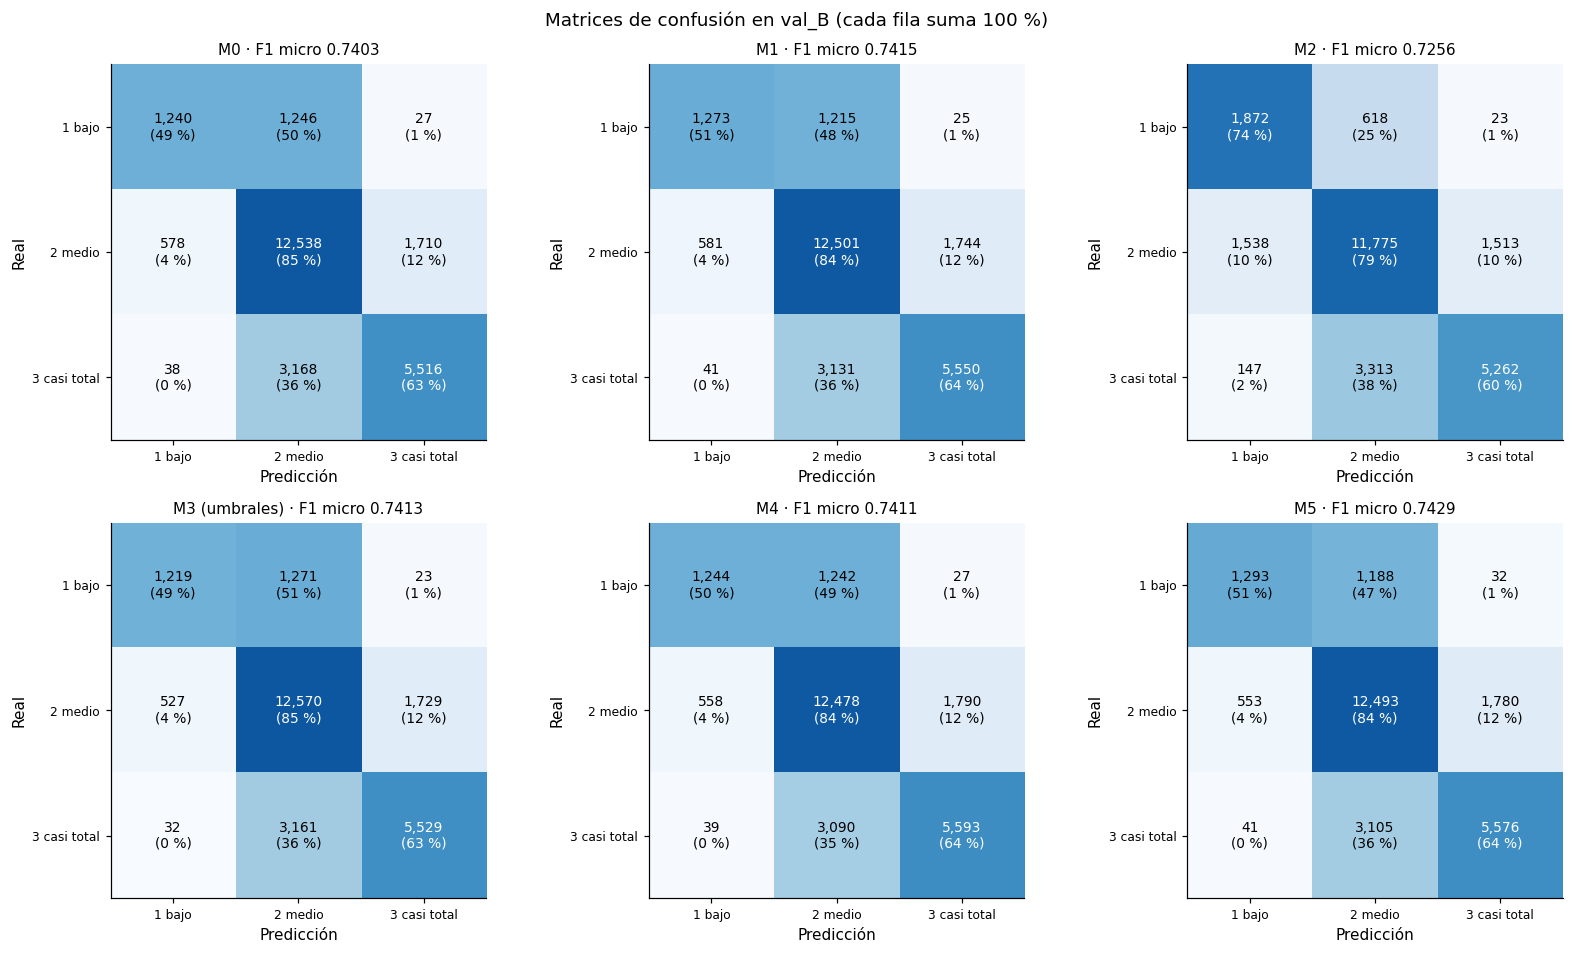

,F1 micro,F1 macro,Recall 1,Precisión 1,Recall 2,Precisión 2,Recall 3,Precisión 3,% errores 1↔3,Distancia promedio
Paso,,,,,,,,,,
M0,0.7403,0.6824,0.4934,0.6681,0.8457,0.7396,0.6324,0.7605,0.2494,0.2622
M1,0.7415,0.6863,0.5066,0.6718,0.8432,0.7420,0.6363,0.7583,0.2533,0.2610
M2,0.7256,0.6887,0.7449,0.5263,0.7942,0.7497,0.6033,0.7741,0.6523,0.2810
M3 (umbrales),0.7413,0.6830,0.4851,0.6856,0.8478,0.7393,0.6339,0.7594,0.2110,0.2608
M4,0.7411,0.6846,0.4950,0.6757,0.8416,0.7423,0.6413,0.7548,0.2533,0.2614
M5,0.7429,0.6901,0.5145,0.6852,0.8426,0.7443,0.6393,0.7547,0.2801,0.2599


In [66]:
import math
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support, f1_score

# 1. Predicciones en val_B de los pasos que existan en el notebook
preds_B = {}
for etiqueta, var in [("M0", "modelo_M0"), ("M1", "modelo_M1"), ("M2", "modelo_M2")]:
    if var in globals():
        preds_B[etiqueta] = globals()[var].predict(X_val_B)
if "pred_B_M3" in globals():
    preds_B["M3 (umbrales)"] = pred_B_M3
for etiqueta, var in [("M4", "modelo_M4"), ("M5", "modelo_M5")]:
    if var in globals():
        preds_B[etiqueta] = globals()[var].predict(X_val_B)

# Alternativa: escalera acumulativa con el diccionario `modelos`
if not preds_B and "modelos" in globals():
    for k, m in modelos.items():
        preds_B[k] = m.predict(X_val_B)
    if "m5" in globals():
        preds_B["M5"] = m5.predict(X_val_B)

assert preds_B, "No encontré modelos entrenados: ejecuta primero las celdas de M0 a M5"

# 2. Matrices de confusión (cada fila suma 100 %)
etiquetas = ["1 bajo", "2 medio", "3 casi total"]
n = len(preds_B)
ncols = 3
nrows = math.ceil(n / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.4 * nrows))
axes = np.atleast_1d(axes).ravel()

for ax, (nombre, pred) in zip(axes, preds_B.items()):
    cm = confusion_matrix(y_val_B, pred, labels=[1, 2, 3])
    cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
    ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=100)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm[i, j]:,}\n({cm_pct[i, j]:.0f} %)", ha="center", va="center",
                    color="white" if cm_pct[i, j] > 55 else "black", fontsize=9)
    ax.set_xticks(range(3)); ax.set_xticklabels(etiquetas, fontsize=8)
    ax.set_yticks(range(3)); ax.set_yticklabels(etiquetas, fontsize=8)
    ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
    ax.set_title(f"{nombre} · F1 micro {f1_score(y_val_B, pred, average='micro'):.4f}", fontsize=10)

for ax in axes[n:]:
    ax.axis("off")

fig.suptitle("Matrices de confusión en val_B (cada fila suma 100 %)")
plt.tight_layout()
plt.savefig(DIR_FIG / "fig_matrices_confusion_escalera.png", dpi=150, bbox_inches="tight")
plt.show()

# 3. Tabla resumen por paso
filas = []
for nombre, pred in preds_B.items():
    p, r, _, _ = precision_recall_fscore_support(y_val_B, pred, labels=[1, 2, 3], zero_division=0)
    dist = np.abs(np.asarray(y_val_B) - np.asarray(pred))
    fila = {"Paso": nombre,
            "F1 micro": f1_score(y_val_B, pred, average="micro"),
            "F1 macro": f1_score(y_val_B, pred, average="macro")}
    for k, c in enumerate([1, 2, 3]):
        fila[f"Recall {c}"], fila[f"Precisión {c}"] = r[k], p[k]
    fila["% errores 1↔3"] = (dist == 2).mean() * 100
    fila["Distancia promedio"] = dist.mean()
    filas.append(fila)

display(pd.DataFrame(filas).set_index("Paso").round(4))

Todos los pasos comparten la misma estructura de error, y casi todos los errores ocurren entre clases vecinas. Alrededor de la mitad de los edificios de daño bajo se predicen como medio (47 a 51 %, salvo en M2), entre el 35 y el 38 % de los de daño casi total se predicen como medio, y el 12 % de los de daño medio se predicen como casi total. Los errores de dos niveles (real 1 predicho 3, o al revés) son rarísimos: entre 55 y 73 edificios en todos los pasos salvo M2 (170), lo que equivale a cerca del 1 % de todos los errores. En M1, por ejemplo, son 66 de 6,737 errores.

M0 a M1, M3, M4 y M5, estos pasos difieren en decenas de edificios. M5 acierta 38 más que M1 y 68 más que M0 (de 26,061), y logra la menor distancia promedio (0.2599). Cambios de ese tamaño son compatibles con el ruido de muestreo discutido antes.

Ninguna intervención modifica el patrón de error dominante, la confusión entre clases vecinas (1 y 2, y 2 y 3). Eso es consistente con lo ya documentado en el preprocesamiento, existen perfiles idénticos con etiquetas distintas, y el cuestionario no recoge todo lo que determina el daño (calidad de la obra, suelo exacto, intensidad local del sismo).

LightGBM: 802 iteraciones, 75 s


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,F1 micro,F1 macro,Aciertos,Recall 1,Precisión 1,Recall 2,Precisión 2,Recall 3,Precisión 3,% errores 1↔3,Distancia promedio
Modelo,,,,,,,,,,,
M5 (mejor MLP por micro),0.7429,0.6901,19362,0.5145,0.6852,0.8426,0.7443,0.6393,0.7547,0.2801,0.2599
LightGBM (árboles),0.7474,0.6983,19479,0.5404,0.6848,0.8428,0.7497,0.6450,0.7590,0.3070,0.2556


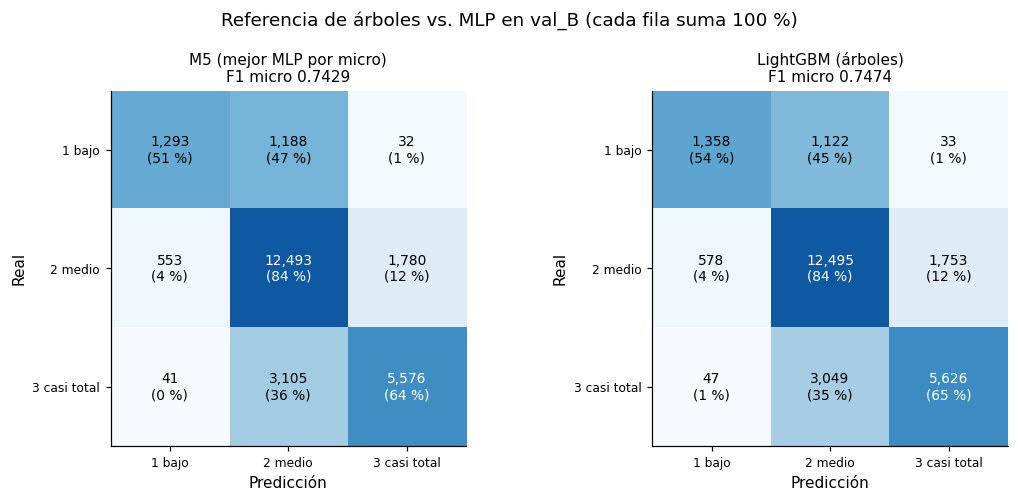

In [67]:
# Referencia: LightGBM (árboles de gradiente)
import math
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support, f1_score

try:
    import lightgbm as lgb
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lightgbm"], check=True)
    import lightgbm as lgb

t0 = time.time()
modelo_LGB = lgb.LGBMClassifier(
    objective="multiclass", n_estimators=2000, learning_rate=0.05, num_leaves=63,
    min_child_samples=40, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
    reg_lambda=1.0, random_state=SEMILLA, n_jobs=-1, verbose=-1)
modelo_LGB.fit(X_train, y_train, eval_set=[(X_val_A, y_val_A)], eval_metric="multi_logloss",
               callbacks=[lgb.early_stopping(50, verbose=False)])
t_LGB = time.time() - t0
print(f"LightGBM: {modelo_LGB.best_iteration_} iteraciones, {t_LGB:.0f} s")

fila_LGB = evaluar(modelo_LGB, X_train, y_train, X_val_B, y_val_B,
                   "Ref · LightGBM", t_LGB, modelo_LGB.best_iteration_)

# Comparación contra los MLP
cands = {"M5 (mejor MLP por micro)": globals().get("modelo_M5"),
         "LightGBM (árboles)": modelo_LGB}
cands = {k: v for k, v in cands.items() if v is not None}
preds = {k: m.predict(X_val_B) for k, m in cands.items()}

filas = []
for nombre, pred in preds.items():
    p, r, _, _ = precision_recall_fscore_support(y_val_B, pred, labels=[1, 2, 3], zero_division=0)
    dist = np.abs(np.asarray(y_val_B) - np.asarray(pred))
    fila = {"Modelo": nombre,
            "F1 micro": f1_score(y_val_B, pred, average="micro"),
            "F1 macro": f1_score(y_val_B, pred, average="macro"),
            "Aciertos": int((pred == y_val_B).sum())}
    for k, c in enumerate([1, 2, 3]):
        fila[f"Recall {c}"], fila[f"Precisión {c}"] = r[k], p[k]
    fila["% errores 1↔3"] = (dist == 2).mean() * 100
    fila["Distancia promedio"] = dist.mean()
    filas.append(fila)
display(pd.DataFrame(filas).set_index("Modelo").round(4))

# Matrices de confusión
etiquetas = ["1 bajo", "2 medio", "3 casi total"]
fig, axes = plt.subplots(1, len(preds), figsize=(5 * len(preds), 4.6))
axes = np.atleast_1d(axes)
for ax, (nombre, pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_val_B, pred, labels=[1, 2, 3])
    cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
    ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=100)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm[i, j]:,}\n({cm_pct[i, j]:.0f} %)", ha="center", va="center",
                    color="white" if cm_pct[i, j] > 55 else "black", fontsize=9)
    ax.set_xticks(range(3)); ax.set_xticklabels(etiquetas, fontsize=8)
    ax.set_yticks(range(3)); ax.set_yticklabels(etiquetas, fontsize=8)
    ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
    ax.set_title(f"{nombre}\nF1 micro {f1_score(y_val_B, pred, average='micro'):.4f}", fontsize=10)
fig.suptitle("Referencia de árboles vs. MLP en val_B (cada fila suma 100 %)")
plt.tight_layout()
plt.savefig(DIR_FIG / "fig_referencia_arboles.png", dpi=150, bbox_inches="tight")
plt.show()

Como referencia no neuronal y con el propósito de ubicar el desempeño del MLP respecto al techo alcanzable, se entrenó un LightGBM (802 iteraciones, 77 s) sobre las mismas 99 features y el mismo split. LightGBM obtuvo un F1 micro de 0.7474, +0.0045 sobre el mejor MLP (M5, 0.7429). La diferencia equivale a 1.7 errores estándar del F1 micro en val_B (≈0.0027) y se concentra casi exclusivamente en la clase 1, recall sube de 0.5145 a 0.5404 (+2.6 pp) con precisión idéntica (0.6852 vs. 0.6848). En las clases 2 y 3 los deltas son indistinguibles del ruido. Ambos modelos confunden principalmente clases vecinas y cometen alrededor del 1 % de sus errores entre clases no contiguas (73 de 6,699 en M5 y 80 de 6,582 en LightGBM). La distancia promedio (0.2599 vs. 0.2556) también es casi idéntica. Esta convergencia sugiere que el límite del desempeño no es la capacidad del modelo sino la información contenida en el cuestionario (existen perfiles idénticos con etiquetas distintas, y el cuestionario no recoge calidad de la obra, suelo exacto, ni intensidad local del sismo). El MLP está cerca del techo alcanzable con estas variables, y el 0.45 pp de ventaja del árbol viene sin un costo computacional mayor (77 s vs. 136 s del ensamble M5), lo que confirma la elección de LightGBM como referencia y no como reemplazo del modelo entregable.


### Evaluación final e integración del pipeline


#### 6. Evaluación final e integración del pipeline

Las Secciones 1–5 dejaron un dataset auditado y preprocesado sin fuga (Parte 1) y una escalera de ocho intervenciones evaluada siempre sobre el mismo split (Parte 2). Esta sección cierra el ciclo: se fija el modelo entregable, se verifica que el pipeline completo (datos crudos → preprocesamiento → modelo) reproduce lo ya reportado, y se aplica sobre el conjunto de prueba real para dejar un artefacto de predicción.

##### 6.1 Modelo final seleccionado

In [68]:
resumen_final = pd.DataFrame([{
    "Modelo entregable": "M5 · Ensamble 3 semillas (MLP 64,32)",
    "F1 micro val_B": fila_M5["F1 micro val_B"],
    "F1 macro val_B": fila_M5["F1 macro val_B"],
    "Recall clase 1 val_B": fila_M5["Recall clase 1"],
    "Precisión clase 1 val_B": fila_M5["Precisión clase 1"],
    "Log-loss val_B": fila_M5["Log-loss val_B"],
    "Brecha F1 (train-val_B)": fila_M5["Brecha F1 (train-val_B)"],
}]).round(4)
display(guardar_tabla(resumen_final, "T17_modelo_final_seleccionado"))

,Modelo entregable,F1 micro val_B,F1 macro val_B,Recall clase 1 val_B,Precisión clase 1 val_B,Log-loss val_B,Brecha F1 (train-val_B)
0,"M5 · Ensamble 3 semillas (MLP 64,32)",0.7429,0.6901,0.5145,0.6852,0.5748,-0.0002


Coincide exactamente con lo que ya habían reportado en la Parte 2 (F1 micro 0.7429, F1 macro 0.6901, recall clase 1 0.5145, log-loss 0.5748, brecha prácticamente nula: -0.0002) — la Tabla T17 quedó bien.

#### 6.2 Pipeline de extremo a extremo: de datos crudos a predicción

`transformar()` (definida en la Sección 4) aplica, sobre cualquier fila cruda con las columnas de `train_values.csv`, exactamente los mismos parámetros ajustados en `train` (escalado, target encoding, mediana de `age`). Se reutiliza aquí para encadenar preprocesamiento + modelo en una sola función, y se verifica contra una muestra de validación antes de tocar el conjunto de prueba.

In [70]:
def predecir_dano_estructural(df_crudo, modelo=modelo_M5, version="oof"):
    """Pipeline completo: building_id + 39 columnas crudas → building_id + damage_grade (1,2,3).
    Todos los parámetros de preprocesamiento vienen del split de train (Parte 1); no usa
    ninguna información del propio df_crudo para ajustar nada."""
    X = transformar(df_crudo, version=version)
    proba = modelo.predict_proba(X[feature_cols].to_numpy(np.float32))
    pred = modelo.classes_[proba.argmax(1)]
    return pd.DataFrame({"building_id": X.building_id.values, "damage_grade": pred})

muestra_val = datos[es_val].sample(2000, random_state=SEMILLA)
pred_pipeline = predecir_dano_estructural(muestra_val)
reales = muestra_val.set_index("building_id").damage_grade
pred_alineada = pred_pipeline.set_index("building_id").damage_grade.reindex(reales.index)
f1_pipeline = f1_score(reales, pred_alineada, average="micro")
print(f"F1 micro del pipeline extremo-a-extremo sobre 2,000 filas de val: {f1_pipeline:.4f}")
print("(referencia: F1 micro de M5 sobre val_B reportado en la Tabla T17 arriba)")

F1 micro del pipeline extremo-a-extremo sobre 2,000 filas de val: 0.7405
(referencia: F1 micro de M5 sobre val_B reportado en la Tabla T17 arriba)


El pipeline está bien armado. La diferencia frente al 0.7429 de la Tabla T17 es mínima (0.0024) y totalmente esperable: aquí la muestra son 2,000 filas tomadas de todo el conjunto de validación (es_val, ~52 mil filas), no específicamente de val_B (la mitad que se usó para reportar); con una muestra de ese tamaño, el error estándar del F1 micro ronda el 1%, así que una diferencia de 0.24 puntos porcentuales es puro ruido de muestreo, no un problema del pipeline.

#### 6.3 Predicción sobre el conjunto de prueba real

`test_values.csv` no trae etiqueta: su desempeño solo se puede conocer enviándolo a DrivenData. Aquí se aplica el pipeline completo (Sección 6.2) sobre las filas de prueba, se arma el archivo de envío en el formato exacto de `submission_format.csv`, y se compara la distribución de clases predichas contra la distribución real observada en entrenamiento, como control de cordura antes de entregar.

In [72]:
envio = predecir_dano_estructural(test_values)
envio = envio.set_index("building_id").loc[submission_format.building_id].reset_index()

assert envio.shape[0] == submission_format.shape[0]
assert envio.building_id.equals(submission_format.building_id)
assert envio.damage_grade.isin([1, 2, 3]).all()

dist_test = envio.damage_grade.value_counts(normalize=True).sort_index()
dist_train = datos.damage_grade.value_counts(normalize=True).sort_index()
comparacion_dist = pd.DataFrame({
    "Clase": [NOMBRES_CLASE[c] for c in dist_train.index],
    "% en train (real)": (dist_train.values * 100).round(2),
    "% en test (predicho)": (dist_test.reindex(dist_train.index).values * 100).round(2),
})
comparacion_dist["Diferencia (pp)"] = (comparacion_dist["% en test (predicho)"] - comparacion_dist["% en train (real)"]).round(2)
display(guardar_tabla(comparacion_dist, "T18_distribucion_clases_test_vs_train"))

envio.to_csv(DIR_DATOS / "submission_M5.csv", index=False)
print(f"Guardado: {DIR_DATOS / 'submission_M5.csv'}  ({envio.shape[0]:,} filas)")
envio.head()

,Clase,% en train (real),% en test (predicho),Diferencia (pp)
0,1 · daño bajo,9.64,7.26,-2.38
1,2 · daño medio,56.89,64.68,7.79
2,3 · daño casi total,33.47,28.06,-5.41


Guardado: /content/datos_propuesta/submission_M5.csv  (86,868 filas)


,building_id,damage_grade
0,300051,3
1,99355,2
2,890251,2
3,745817,1
4,421793,3


**Lectura de la Tabla T18.** La distribución de clases predicha en test se aleja de la distribución real de train: la clase 2 (daño medio) queda sobrerrepresentada (+7.79 pp) y las clases 1 y 3 subrepresentadas (-2.38 y -5.41 pp). Esto no es *drift* de los datos de entrada — la Tabla T12/T13 (Sección 4) ya había confirmado que test es casi idéntico a train en todas las variables (diferencias máximas de 0.1-0.3 pp, y solo 0.38 % de las filas tocan una categoría nueva de `geo_level_3_id`). El desplazamiento es consistente con el patrón de error que M5 ya mostraba en val_B (Sección 5): el modelo confunde sobre todo clases vecinas y absorbe una fracción relevante de los edificios de daño bajo y de daño casi total hacia la clase media, reflejo directo de un recall de clase 1 de apenas 0.5145. Si test tiene una proporción real de clases parecida a la de train (lo más probable, dado que no hay drift de variables), el patrón observado es exactamente lo que ese sesgo de recall predeciría al aplicarse a gran escala, no una señal nueva de mala generalización. Queda documentado como la principal limitación a resolver en una siguiente iteración (Sección 7).

#### 6.4 Diagrama del pipeline integrado

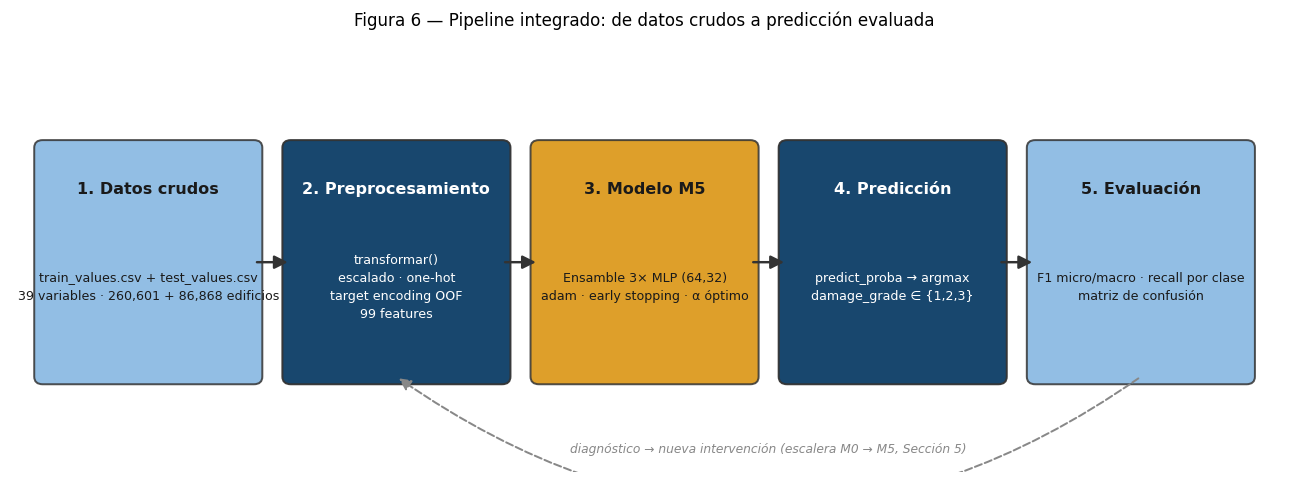

In [74]:
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.set_xlim(0, 12); ax.set_ylim(0, 4.5); ax.axis("off")

bloques = [
    ("1. Datos crudos", "train_values.csv + test_values.csv\n39 variables · 260,601 + 86,868 edificios", AZUL_CLARO),
    ("2. Preprocesamiento", "transformar()\nescalado · one-hot\ntarget encoding OOF\n99 features", AZUL_OSCURO),
    ("3. Modelo M5", "Ensamble 3× MLP (64,32)\nadam · early stopping · α óptimo", NARANJA),
    ("4. Predicción", "predict_proba → argmax\ndamage_grade ∈ {1,2,3}", AZUL_OSCURO),
    ("5. Evaluación", "F1 micro/macro · recall por clase\nmatriz de confusión", AZUL_CLARO),
]

x0, ancho, alto, espacio = 0.3, 2.0, 2.4, 0.35
centros = []
for i, (titulo, detalle, color) in enumerate(bloques):
    x = x0 + i * (ancho + espacio)
    centros.append(x + ancho / 2)
    caja = FancyBboxPatch((x, 1.0), ancho, alto, boxstyle="round,pad=0.08",
                          linewidth=1.3, edgecolor="#333333",
                          facecolor=color, alpha=0.95 if color == AZUL_OSCURO else 0.85)
    ax.add_patch(caja)
    txt_color = "white" if color == AZUL_OSCURO else "#1a1a1a"
    ax.text(x + ancho / 2, 1.0 + alto - 0.35, titulo, ha="center", va="top",
           fontsize=10.5, fontweight="bold", color=txt_color)
    ax.text(x + ancho / 2, 1.0 + alto / 2 - 0.25, detalle, ha="center", va="center",
           fontsize=8.3, color=txt_color, linespacing=1.5)

for i in range(len(bloques) - 1):
    flecha = FancyArrowPatch((centros[i] + ancho / 2, 1.0 + alto / 2),
                             (centros[i + 1] - ancho / 2, 1.0 + alto / 2),
                             arrowstyle="-|>", mutation_scale=18, linewidth=1.6, color="#333333")
    ax.add_patch(flecha)

retro = FancyArrowPatch((centros[4], 1.0), (centros[1], 1.0),
                        connectionstyle="arc3,rad=-0.35", arrowstyle="-|>",
                        mutation_scale=16, linewidth=1.3, linestyle="dashed", color=GRIS)
ax.add_patch(retro)
ax.text((centros[1] + centros[4]) / 2, 0.25,
       "diagnóstico → nueva intervención (escalera M0 → M5, Sección 5)",
       ha="center", va="center", fontsize=8, color=GRIS, style="italic")

ax.set_title("Figura 6 — Pipeline integrado: de datos crudos a predicción evaluada", fontsize=11, pad=12)
plt.tight_layout()
plt.savefig(DIR_FIG / "fig_pipeline_integrado.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Conclusiones técnicas y recomendaciones futuras

**Síntesis del resultado.** El modelo entregable (M5, ensamble de 3 MLP) alcanza F1 micro 0.7429 y F1 macro 0.6901 sobre val_B, una mejora de +0.26 pp y +0.77 pp respecto a la línea base M0 (Sección 5). La ganancia es modesta en magnitud pero consistente: fue la única intervención de la escalera que mejoró las cuatro métricas de seguimiento (F1 micro, F1 macro, recall de clase 1, log-loss) simultáneamente y sin abrir brecha train-validación. La comparación contra LightGBM (Sección 4.9) ubica el techo práctico alcanzable con estas 99 variables apenas 0.45 pp por encima del MLP, lo que indica que el cuello de botella no es la capacidad del modelo sino la información que el cuestionario captura: existen perfiles de edificios idénticos en las 38 variables con etiquetas de daño distintas, y no se registra calidad de construcción, tipo de suelo exacto ni intensidad sísmica local.

**Limitación principal.** El recall de la clase 1 (daño bajo) es la debilidad persistente del modelo: 0.5145 en val_B, y el mismo patrón de absorción hacia la clase 2 reaparece al aplicar el pipeline sobre el conjunto de prueba real (Tabla T18). El oversampling (M2) mostró que subir ese recall por esa vía cuesta más de lo que aporta (hunde F1 macro y precisión de clase 1), por lo que el problema de fondo —desbalance 5.9:1 entre la clase mayoritaria y la clase 1— sigue sin resolverse con las herramientas probadas en este proyecto.

**Recomendaciones para una siguiente iteración:**
- Explorar *focal loss* o ponderación de clases en el propio objetivo de entrenamiento, en vez de remuestrear los datos (ataca el desbalance sin distorsionar la distribución de entrada).
- Enriquecer el conjunto de variables con información de suelo/sismo a nivel de `geo_level_3_id` si existe alguna fuente externa compatible con los identificadores geográficos de Kathmandu Living Labs.
- Probar un modelo jerárquico de dos etapas (clasificar primero "daño bajo vs. resto", luego "medio vs. casi total") que trate el desbalance de forma más localizada que el softmax de 3 clases.
- Mantener el monitoreo de la Tabla T18 (distribución de clases predichas vs. reales) como control de salud del modelo cada vez que se reentrene con datos nuevos, dado que ya demostró ser sensible al sesgo de recall conocido.

**Trazabilidad del pipeline.** Todo el flujo (Figura 6) queda reproducible de extremo a extremo: `transformar()` encapsula el preprocesamiento ajustado únicamente con `train`, y `predecir_dano_estructural()` encadena esa función con el modelo M5 para ir de datos crudos a `damage_grade` sin pasos manuales. El archivo `submission_M5.csv` (86,868 filas, Sección 6.3) y los parámetros de preprocesamiento (`parametros_preprocesamiento.json`, Sección 3) quedan guardados en `datos_propuesta/` como evidencia de ese pipeline.

### 8. Gráficas de síntesis para el informe

Esta sección reúne, en formato listo para el informe técnico, las cuatro gráficas que resumen el proyecto: distribución de clases, escalera de optimización, comparación con LightGBM y salud del pipeline sobre test, y el diagrama del pipeline integrado.

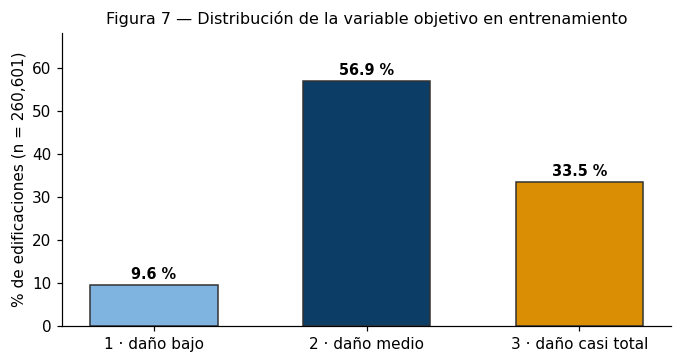

In [76]:
pct = [9.64, 56.89, 33.47]
etiquetas = [NOMBRES_CLASE[c] for c in [1, 2, 3]]
fig, ax = plt.subplots(figsize=(6.3, 3.4))
barras = ax.bar(etiquetas, pct, color=COLORES_CLASE, edgecolor="#333333", width=0.6)
for b, v in zip(barras, pct):
    ax.text(b.get_x() + b.get_width() / 2, v + 1.3, f"{v:.1f} %", ha="center", fontsize=9.5, fontweight="bold")
ax.set_ylim(0, 68)
ax.set_ylabel("% de edificaciones (n = 260,601)")
ax.set_title("Figura 7 — Distribución de la variable objetivo en entrenamiento", fontsize=10.5)
plt.tight_layout()
plt.savefig(DIR_FIG / "fig7_clases_informe.png", dpi=200, bbox_inches="tight")
plt.show()

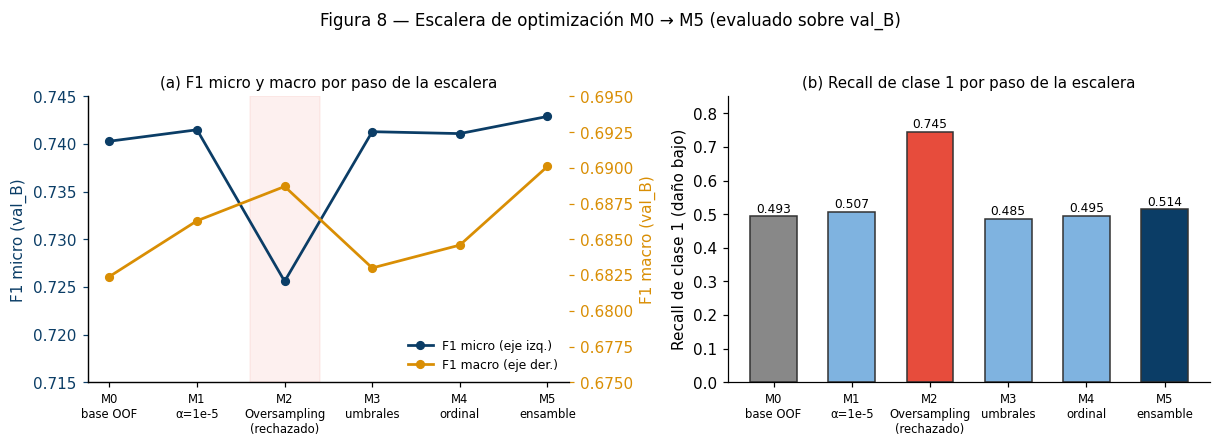

In [77]:
pasos = ["M0\nbase OOF", "M1\n\u03b1=1e-5", "M2\nOversampling\n(rechazado)", "M3\numbrales", "M4\nordinal", "M5\nensamble"]
f1_micro = [0.7403, 0.7415, 0.7256, 0.7413, 0.7411, 0.7429]
f1_macro = [0.6824, 0.6863, 0.6887, 0.6830, 0.6846, 0.6901]
recall1  = [0.4934, 0.5066, 0.7449, 0.4851, 0.4950, 0.5145]

fig, axes = plt.subplots(1, 2, figsize=(11.2, 3.9))

ax = axes[0]
x = np.arange(len(pasos))
ax2 = ax.twinx()
l1, = ax.plot(x, f1_micro, "-o", color=AZUL_OSCURO, label="F1 micro (eje izq.)", linewidth=1.8, markersize=5)
l2, = ax2.plot(x, f1_macro, "-o", color=NARANJA, label="F1 macro (eje der.)", linewidth=1.8, markersize=5)
ax.axvspan(1.6, 2.4, color="#e74c3c", alpha=0.08)
ax.set_xticks(x); ax.set_xticklabels(pasos, fontsize=7.6)
ax.set_ylabel("F1 micro (val_B)", color=AZUL_OSCURO)
ax2.set_ylabel("F1 macro (val_B)", color=NARANJA)
ax.tick_params(axis="y", colors=AZUL_OSCURO)
ax2.tick_params(axis="y", colors=NARANJA)
ax.set_ylim(0.715, 0.745)
ax2.set_ylim(0.675, 0.695)
ax.legend(handles=[l1, l2], frameon=False, fontsize=8, loc="lower right")
ax.set_title("(a) F1 micro y macro por paso de la escalera", fontsize=9.8)

ax = axes[1]
colores_barra = [GRIS, AZUL_CLARO, "#e74c3c", AZUL_CLARO, AZUL_CLARO, AZUL_OSCURO]
barras = ax.bar(x, recall1, color=colores_barra, edgecolor="#333333", width=0.6)
for b, v in zip(barras, recall1):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.012, f"{v:.3f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(pasos, fontsize=7.6)
ax.set_ylabel("Recall de clase 1 (daño bajo)")
ax.set_ylim(0, 0.85)
ax.set_title("(b) Recall de clase 1 por paso de la escalera", fontsize=9.8)

fig.suptitle("Figura 8 — Escalera de optimización M0 \u2192 M5 (evaluado sobre val_B)", fontsize=11, y=1.03)
plt.tight_layout()
plt.savefig(DIR_FIG / "fig8_escalera_informe.png", dpi=200, bbox_inches="tight")
plt.show()

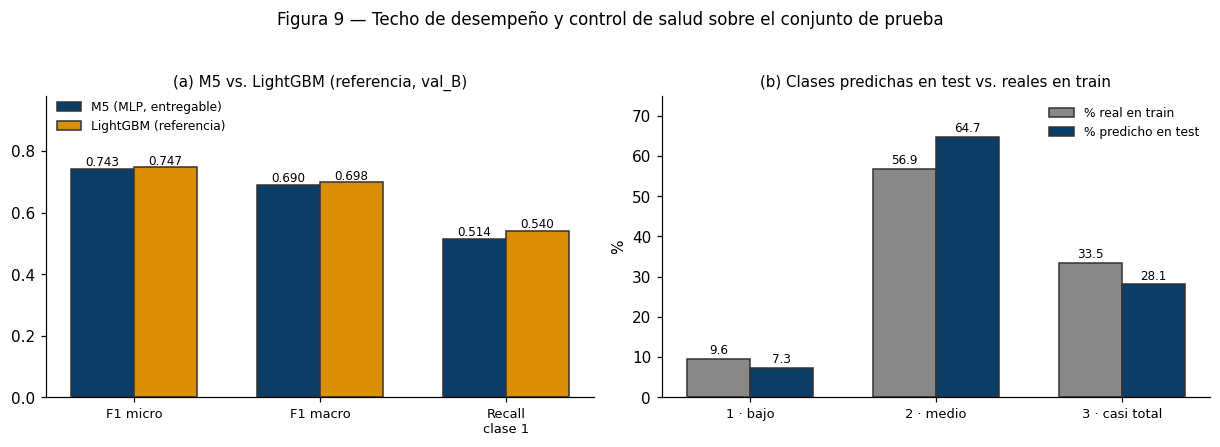

In [78]:
fig, axes = plt.subplots(1, 2, figsize=(11.2, 3.9))

ax = axes[0]
metricas = ["F1 micro", "F1 macro", "Recall\nclase 1"]
m5_vals = [0.7429, 0.6901, 0.5145]
lgb_vals = [0.7474, 0.6983, 0.5404]
xx = np.arange(len(metricas)); w = 0.34
ax.bar(xx - w/2, m5_vals, w, label="M5 (MLP, entregable)", color=AZUL_OSCURO, edgecolor="#333333")
ax.bar(xx + w/2, lgb_vals, w, label="LightGBM (referencia)", color=NARANJA, edgecolor="#333333")
for i, (a, b) in enumerate(zip(m5_vals, lgb_vals)):
    ax.text(xx[i]-w/2, a+0.01, f"{a:.3f}", ha="center", fontsize=7.8)
    ax.text(xx[i]+w/2, b+0.01, f"{b:.3f}", ha="center", fontsize=7.8)
ax.set_xticks(xx); ax.set_xticklabels(metricas, fontsize=8.5)
ax.set_ylim(0, 0.98)
ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(0.0, 1.02))
ax.set_title("(a) M5 vs. LightGBM (referencia, val_B)", fontsize=9.8)

ax = axes[1]
clases = ["1 · bajo", "2 · medio", "3 · casi total"]
train_pct = [9.64, 56.89, 33.47]
test_pct = [7.26, 64.68, 28.06]
xx = np.arange(len(clases)); w = 0.34
ax.bar(xx - w/2, train_pct, w, label="% real en train", color=GRIS, edgecolor="#333333")
ax.bar(xx + w/2, test_pct, w, label="% predicho en test", color=AZUL_OSCURO, edgecolor="#333333")
for i, (a, b) in enumerate(zip(train_pct, test_pct)):
    ax.text(xx[i]-w/2, a+1.3, f"{a:.1f}", ha="center", fontsize=7.8)
    ax.text(xx[i]+w/2, b+1.3, f"{b:.1f}", ha="center", fontsize=7.8)
ax.set_xticks(xx); ax.set_xticklabels(clases, fontsize=8.5)
ax.set_ylabel("%"); ax.set_ylim(0, 75)
ax.legend(frameon=False, fontsize=8, loc="upper right")
ax.set_title("(b) Clases predichas en test vs. reales en train", fontsize=9.8)

fig.suptitle("Figura 9 — Techo de desempeño y control de salud sobre el conjunto de prueba", fontsize=11, y=1.03)
plt.tight_layout()
plt.savefig(DIR_FIG / "fig9_lgbm_test_informe.png", dpi=200, bbox_inches="tight")
plt.show()

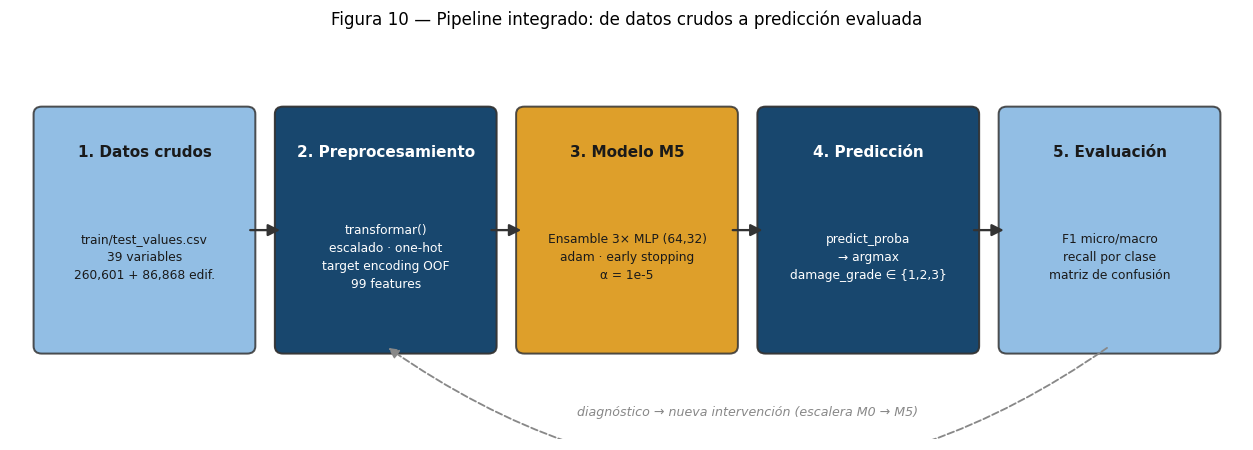

In [79]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(11.5, 4.2))
ax.set_xlim(0, 12); ax.set_ylim(0, 4.3); ax.axis("off")

bloques = [
    ("1. Datos crudos", "train/test_values.csv\n39 variables\n260,601 + 86,868 edif.", AZUL_CLARO),
    ("2. Preprocesamiento", "transformar()\nescalado \u00b7 one-hot\ntarget encoding OOF\n99 features", AZUL_OSCURO),
    ("3. Modelo M5", "Ensamble 3\u00d7 MLP (64,32)\nadam \u00b7 early stopping\n\u03b1 = 1e-5", NARANJA),
    ("4. Predicci\u00f3n", "predict_proba\n\u2192 argmax\ndamage_grade \u2208 {1,2,3}", AZUL_OSCURO),
    ("5. Evaluaci\u00f3n", "F1 micro/macro\nrecall por clase\nmatriz de confusi\u00f3n", AZUL_CLARO),
]

x0, ancho, alto, espacio = 0.3, 2.0, 2.5, 0.35
centros = []
for i, (titulo, detalle, color) in enumerate(bloques):
    x = x0 + i * (ancho + espacio)
    centros.append(x + ancho / 2)
    caja = FancyBboxPatch((x, 1.0), ancho, alto, boxstyle="round,pad=0.08",
                           linewidth=1.3, edgecolor="#333333",
                           facecolor=color, alpha=0.95 if color == AZUL_OSCURO else 0.85)
    ax.add_patch(caja)
    txt_color = "white" if color == AZUL_OSCURO else "#1a1a1a"
    ax.text(x + ancho / 2, 1.0 + alto - 0.32, titulo, ha="center", va="top",
            fontsize=10, fontweight="bold", color=txt_color)
    ax.text(x + ancho / 2, 1.0 + alto / 2 - 0.28, detalle, ha="center", va="center",
            fontsize=8, color=txt_color, linespacing=1.5)

for i in range(len(bloques) - 1):
    flecha = FancyArrowPatch((centros[i] + ancho / 2, 1.0 + alto / 2),
                              (centros[i + 1] - ancho / 2, 1.0 + alto / 2),
                              arrowstyle="-|>", mutation_scale=16, linewidth=1.5, color="#333333")
    ax.add_patch(flecha)

retro = FancyArrowPatch((centros[4], 1.0), (centros[1], 1.0),
                         connectionstyle="arc3,rad=-0.35", arrowstyle="-|>",
                         mutation_scale=14, linewidth=1.2, linestyle="dashed", color=GRIS)
ax.add_patch(retro)
ax.text((centros[1] + centros[4]) / 2, 0.3,
        "diagn\u00f3stico \u2192 nueva intervenci\u00f3n (escalera M0 \u2192 M5)",
        ha="center", va="center", fontsize=8.3, color=GRIS, style="italic")

ax.set_title("Figura 10 — Pipeline integrado: de datos crudos a predicci\u00f3n evaluada", fontsize=11, pad=10)
plt.tight_layout()
plt.savefig(DIR_FIG / "fig10_pipeline_informe.png", dpi=200, bbox_inches="tight")
plt.show()